# COMP2200/COMP6200 Assignment 1

Due date: 11:55pm on Sunday April 6th 2025

(Note that daylight savings ends earlier on that day. Remember to move your clock backward by an hour.)

## Scenario

You are working as a data scientist in a venture capital investment firm. You have been given some
data about a potential company to invest in. You will create some models to predict what the 
potential company will be like in 12 months' time.


## About this assignment

This assessment focuses on fundamental statistical analysis, which
will apply linear and logistic regression techniques on one or more
data sets.

The relevant ULO (Unit Learning Outcomes) are:

- Identify the appropriate Data Science analysis for a problem and
  apply that method to the problem.

- Interpret Data Science analyses and summarise and identify the most
  important aspects of a Data Science analysis.

- Present the results of their Data Science analyses both verbally and
  in written form.
  
Total: 15 marks
  

## Submission

Use https://classroom.github.com/a/BdRkY5OH to create a new empty
repository.

Complete this notebook and add it to a new GitHub repository.

Submit this repository via Github Classroom.

Add the video that you create (in the last step) to your GitHub repository.

You don't need to submit your CSV data file, but we won't penalise you
if you do.

## Use of Generative AI

Feel free to use Gen-AI tools (ChatGPT, Anthropic Claude, DeepSeek,
Llama, etc.) to assist you in writing the code. That's what everyone
in industry does nowadays. There are some suggested prompts at the bottom
of this notebook.

Remember that you may be called on to explain what your code does and
how it works, so if you have some code generated for you that you
don't fully understand, spend some time with your Gen-AI tool asking
for clarification until you are confident. Having a personal tutor
guide you is one of the newest and fastest ways to learn to program in
Python, so make the most of the opportunity. 

To help you remember what your code does, you can add comments to your
code either by creating another markdown cell, or by using "#" at the
beginning of a line in a code cell.

Don't use Gen-AI tools for writing reflections and observations. You
will find many cells in this notebook where you need to enter markdown text.
They appear like this:

**Your answer here. Replace the text in this markdown cell. Remember not to use Gen-AI here.**

You don't want to use Gen-AI in these cells for two reasons:

- Thinking and reflecting is how you will get most of the benefit of doing this assignment.

- It will produce meaningless and bland statements (that will be obviously meaningless and bland)
  and you will get bad marks.
  

## Marking Criteria

For a code cell, any working correct answer will earn full marks. For
non-working code, or code that performs a different task, if it seems
like you were on the right track, the marker may issue partial marks.

For code cells that create visualisations, a correct answer is one that
creates a meaningful and useful visualisation of the data.

For a text (markdown) cell, word counts are only a guide: this is how
many words we think it will take to give a good answer. If you need to
use more words, or can express your answer in less words, go ahead: a
good answer will still receive full marks.

Answers given as dot points in a markdown cell are acceptable;
likewise full sentences in paragraphs are acceptable.

## Resources

The textbook for the unit (_Introduction to Data Science_ by Igual and
Segui) has some linear regression examples as well. You might find
Section 6.2.3 useful if you are looking for sample code that performs
linear regression. Section 6.3.1 has an example of logistic
regression.


## Data

You will find a large zip file called `2025-S1-COMP2200-6200-assignment1.zip` on iLearn.  When you expand it
out, you will see many files, including one that begins with your
student number. e.g `1235345 Brown-Miller Group.csv`

Copy it into the same directory as you copied this Jupyter notebook.

### Create a GitHub repo within Github Classroom (0.1 marks)

- Yes, we'll give you 0.1 marks just for getting this far.

### Import any libraries you need (0.1 marks)



---
# Live Investment Committee Presentation: Garza Inc & Sons — 12-Month Outlook

**Prepared by:** Data Science Team (Venture Capital Analytics) &nbsp;|&nbsp; **Audience:** Investment Committee &nbsp;|&nbsp; **Data Span:** Months 1–24 (`n = 24`)

### Executive TL;DR — Where Garza Stands in 12 Months (Month 36)

| Dimension | Month 24 Actual | Month 36 Forecast | 95% Prediction Interval | Model & Confidence |
|---|---|---|---|---|
| **Monthly Payroll** | `$2.99M` | **`$3.74M / mo`** (`+$64.6k/mo`) | `$3.55M – $3.93M` | Huber Robust (**High**) |
| **Monthly Revenue** | `$749k` | **`$3.66M / mo`** median (`$3.74M` mean) | `$2.01M – $6.65M` | Log10-Linear (**Moderate–Low**) |
| **Net (Rev − Payroll)** | `-$2.24M` | **`-$84k / mo`** *(breakeven ~M36–37)* | `-$1.92M` (Bear) to `+$3.10M` (Bull) | Combined Financial (**Moderate**) |
| **Media Coverage** | `Negative` (M11–24) | **`99.99%` `Negative`** *(assuming 0 scandals)* | Insensitive across 95% bounds | Std. Logistic (**Low Causal**) |
| **VC Decision Stance** | — | **`CONDITIONAL DUE DILIGENCE`** | — | Audit M11 Spike, M14 Scandal & PR |

### Presentation Agenda (6-Act Walkthrough)
1. **Act 1 — Data Audit & Anomaly Discovery:** Complete 24-month health check and Month 11 `$5.97M` payroll spike (`2.83×` trend).
2. **Act 2 — Cost Structure Modeling:** OLS vs. Huber robust payroll forecasting with rolling CV and widening 95% prediction intervals.
3. **Act 3 — Growth Engine Modeling:** Log-linear revenue modeling (`+16.7%/mo`), apples-to-apples dollar validation, and 20-year sanity check.
4. **Act 4 — Reputational Risk Modeling:** Standardized logistic regression, Month 10→11 regime separation, and Month 36 risk forecast.
5. **Act 5 — Executive Synthesis & Dashboard:** Integrated 3-panel financial/media outlook and committee summary.
6. **Act 6 — Live 5-Slide Executive Deck:** Non-technical boardroom summary, Bear/Base/Bull stress test, assumptions, and 30-day diligence plan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
from scipy import stats

from sklearn.linear_model import (
    LinearRegression,
    HuberRegressor,
    TheilSenRegressor,
    RANSACRegressor,
    LogisticRegression,
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    LeaveOneOut,
    cross_val_score,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
)

# Consistent publication-grade visual styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica", "Liberation Sans"],
    "text.parse_math": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
    "legend.facecolor": "white",
    "legend.framealpha": 0.92,
})

# Project color palette
PALETTE = {
    "navy": "#1B365D",
    "emerald": "#1B9E77",
    "crimson": "#C0392B",
    "amber": "#D97706",
    "slate": "#64748B",
}

def fmt_dollars_m(x, pos=None):
    sign = "-" if x < 0 else ""
    return f"{sign}${abs(x) / 1e6:.1f}M"

def fmt_dollars_k(x, pos=None):
    sign = "-" if x < 0 else ""
    if abs(x) >= 1e6:
        return f"{sign}${abs(x) / 1e6:.2f}M"
    return f"{sign}${abs(x) / 1e3:.0f}k"

print("Libraries imported and global visual theme configured.")


Libraries imported and global visual theme configured.




If you are doing something exotic --- e.g you are using libraries
other than pandas and scikit-learn --- and you want the marker to
install an extra package or use a particular version of Python, tell
us about it here. Most students will leave this blank.



No exotic libraries or custom Python environments are required. Beyond `pandas` and `scikit-learn`, this notebook uses standard scientific Python libraries pre-installed in mainstream distributions (`numpy`, `matplotlib`, `seaborn`, and `scipy`).


---
# Act 1 — Data Audit & Payroll Anomaly Discovery

> **Presenter Takeaway:** The 24-month dataset has zero missing values, exponential revenue growth (`68.5×` from M1 to M24), a single extreme payroll spike in **Month 11 (`$5.97M`)**, and a sharp media shift from `Positive` (M1–10) to `Negative` (M11–24).



### Unzip and Load the Data (0.1 marks)

- Load the data into a DataFrame using `pd.read_csv()` into a variable called `df`.



In [2]:
df = pd.read_csv('48474967_Garza_Inc_and_Sons.csv')

print(f"Dataset loaded successfully: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Total missing values: {int(df.isna().sum().sum())}")


Dataset loaded successfully: 24 rows x 6 columns
Total missing values: 0




### Inspect the Data (0.2 marks)

- List the column names using `df.columns`.



In [3]:
df.columns


Index(['Months_Since_Launch', 'Payroll', 'Revenue', 'Base_10_Log_Revenue',
       'Scandals', 'Media Coverage'],
      dtype='str')



- Explore the data in those columns. Briefly describe each column in one sentence.



In [4]:
print("=== Schema & Non-Null Counts ===")
df.info()

print("\n=== Summary Statistics (Numeric Columns) ===")
display(df.describe().T.round(4))

print("\n=== Categorical & Discrete Distributions ===")
print("Media Coverage counts:")
print(df['Media Coverage'].value_counts().to_string())
print("\nScandals counts:")
print(df['Scandals'].value_counts().to_string())

# Verify consistency of pre-computed Base_10_Log_Revenue
max_log_diff = np.max(np.abs(np.log10(df['Revenue']) - df['Base_10_Log_Revenue']))
print(f"\nMax |log10(Revenue) - Base_10_Log_Revenue|: {max_log_diff:.6f}")

print("\n=== Full 24-Month Dataset ===")
display(df)


=== Schema & Non-Null Counts ===
<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Months_Since_Launch  24 non-null     int64  
 1   Payroll              24 non-null     float64
 2   Revenue              24 non-null     float64
 3   Base_10_Log_Revenue  24 non-null     float64
 4   Scandals             24 non-null     int64  
 5   Media Coverage       24 non-null     str    
dtypes: float64(3), int64(2), str(1)
memory usage: 1.4 KB

=== Summary Statistics (Numeric Columns) ===


,count,mean,std,min,25%,50%,75%,max
Months_Since_Launch,24.0,1.250000e+01,7.0711,1.000000e+00,6.750,1.250000e+01,1.825000e+01,2.400000e+01
Payroll,24.0,2.370665e+06,896943.8378,1.483216e+06,1764493.660,2.247551e+06,2.632905e+06,5.966452e+06
Revenue,24.0,1.697931e+05,191060.7602,1.094300e+04,41109.560,8.539185e+04,2.191441e+05,7.494207e+05
Base_10_Log_Revenue,24.0,4.983100e+00,0.4857,4.039100e+00,4.611,4.931400e+00,5.340700e+00,5.874700e+00
Scandals,24.0,4.170000e-02,0.2041,0.000000e+00,0.000,0.000000e+00,0.000000e+00,1.000000e+00



=== Categorical & Discrete Distributions ===
Media Coverage counts:
Media Coverage
Negative    14
Positive    10

Scandals counts:
Scandals
0    23
1     1

Max |log10(Revenue) - Base_10_Log_Revenue|: 0.000048

=== Full 24-Month Dataset ===


,Months_Since_Launch,Payroll,Revenue,Base_10_Log_Revenue,Scandals,Media Coverage
0,1,1483215.58,10943.00,4.0391,0,Positive
1,2,1551277.11,23566.44,4.3723,0,Positive
2,3,1621637.52,28662.87,4.4573,0,Positive
3,4,1729773.95,32194.23,4.5078,0,Positive
4,5,1764506.83,33231.02,4.5215,0,Positive
5,6,1764454.15,28803.68,4.4594,0,Positive
6,7,1676010.38,56065.61,4.7487,0,Positive
7,8,1918706.84,43735.74,4.6408,0,Positive
8,9,2005307.42,56387.46,4.7512,0,Positive
9,10,1993967.85,47681.92,4.6784,0,Positive





Suggested word count: ~100 words



The dataset contains **24 complete monthly observations** (zero missing values) across six columns for Garza Inc and Sons:

- **`Months_Since_Launch`**: Sequential integer index from `1` to `24` tracking the startup's operational age in months.
- **`Payroll`**: Monthly payroll expenditure in USD, rising steadily from `$1.48M` to `$2.99M` across normal months with one extreme spike to `$5.97M` in Month 11.
- **`Revenue`**: Monthly revenue in USD, growing rapidly and non-linearly from `$10,943` in Month 1 to `$749,421` in Month 24.
- **`Base_10_Log_Revenue`**: Base-10 logarithm of `Revenue` (`4.0391` to `5.8747`), compressing exponential growth into a nearly linear trend.
- **`Scandals`**: Binary indicator of reported scandals (`0` for 23 months; `1` once in Month 14).
- **`Media Coverage`**: Categorical press sentiment that is **`Positive` for Months 1–10** (`n=10`) and **`Negative` for all 14 months from Month 11–24** (`n=14`), shifting in the exact month of the payroll spike.




### Visualise Payroll Over Time (1 mark)

- Create a line plot clearly showing payroll over months since launch.



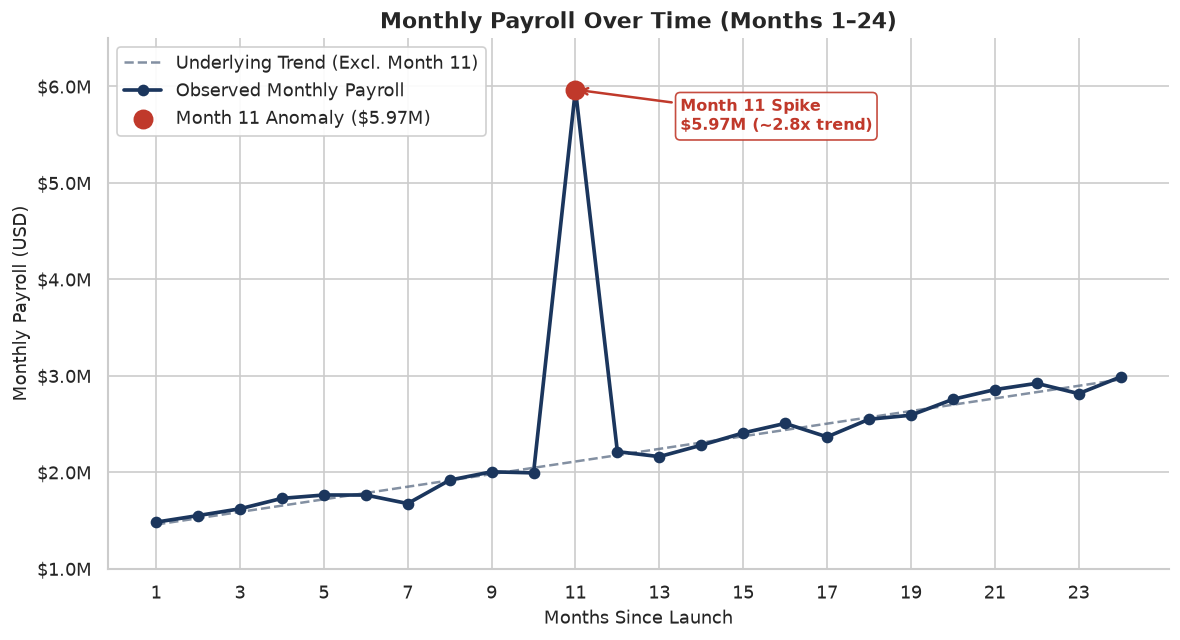

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# Reference linear trend fitted excluding the Month 11 anomaly
non_outlier = df[df['Months_Since_Launch'] != 11]
ref_fit = LinearRegression().fit(non_outlier[['Months_Since_Launch']], non_outlier['Payroll'])
ref_line = ref_fit.predict(df[['Months_Since_Launch']])

ax.plot(
    df['Months_Since_Launch'],
    ref_line,
    linestyle='--',
    color=PALETTE['slate'],
    linewidth=1.5,
    alpha=0.8,
    label='Underlying Trend (Excl. Month 11)',
)
ax.plot(
    df['Months_Since_Launch'],
    df['Payroll'],
    marker='o',
    color=PALETTE['navy'],
    linewidth=2.2,
    markersize=6,
    label='Observed Monthly Payroll',
)

# Highlight Month 11 spike
m11_row = df.loc[df['Months_Since_Launch'] == 11].iloc[0]
ax.scatter(
    [m11_row['Months_Since_Launch']],
    [m11_row['Payroll']],
    color=PALETTE['crimson'],
    s=120,
    zorder=5,
    label='Month 11 Anomaly ($5.97M)',
)
ax.annotate(
    f"Month 11 Spike\n${m11_row['Payroll']/1e6:.2f}M (~2.8x trend)",
    xy=(m11_row['Months_Since_Launch'], m11_row['Payroll']),
    xytext=(13.5, 5.55e6),
    fontsize=9.5,
    fontweight='bold',
    color=PALETTE['crimson'],
    arrowprops=dict(arrowstyle='->', color=PALETTE['crimson'], lw=1.5),
    bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=PALETTE['crimson'], alpha=0.9),
)

ax.set_title('Monthly Payroll Over Time (Months 1–24)')
ax.set_xlabel('Months Since Launch')
ax.set_ylabel('Monthly Payroll (USD)')
ax.set_xticks(range(1, 25, 2))
ax.set_ylim(1.0e6, 6.5e6)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
ax.legend(loc='upper left')
sns.despine(ax=ax)
plt.tight_layout()
plt.show()




- Identify and briefly discuss any visible outliers.



IQR Diagnostics -> Q1: $1,764,493.66 | Q3: $2,632,905.11 | IQR: $868,411.45 | Upper Fence (Q3 + 1.5*IQR): $3,935,522.29
Detected IQR Outliers: 1 row(s) -> Month(s) [11]
Month 11 vs Clean Trend -> Expected: $2,111,999.85 | Actual: $5,966,451.61 | Residual: +$3,854,451.76 (2.83x)


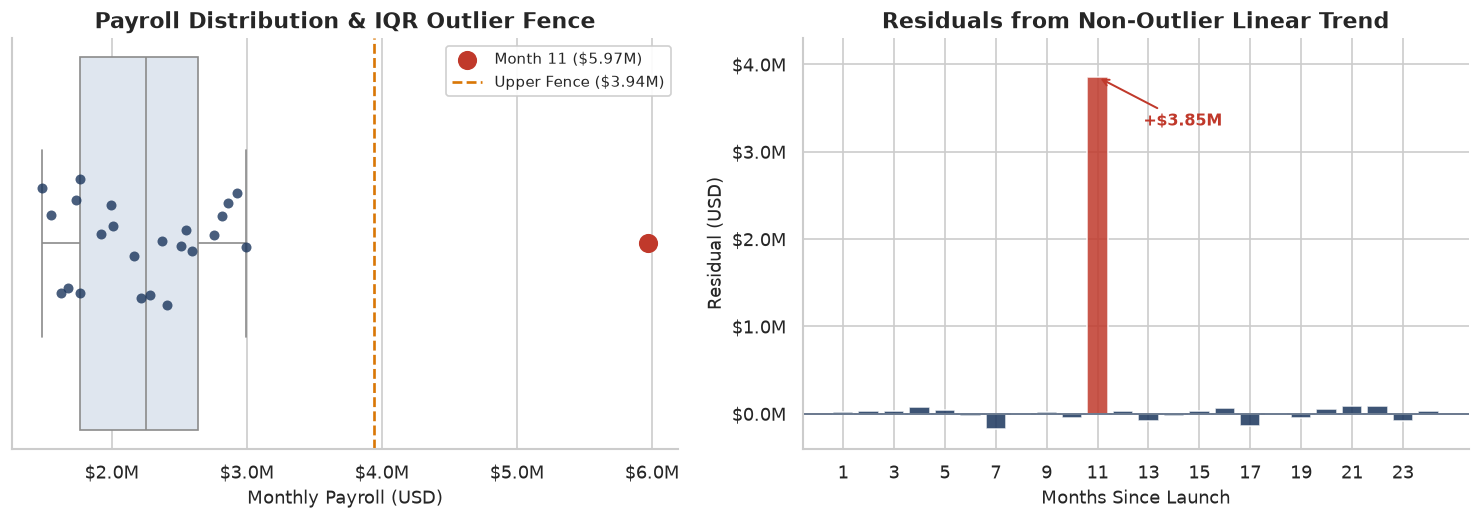

In [6]:
# Quantitative IQR and trend-residual outlier diagnostics
q1, q3 = df['Payroll'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outliers = df[df['Payroll'] > upper_fence]

clean_df = df[df['Months_Since_Launch'] != 11]
clean_lr = LinearRegression().fit(clean_df[['Months_Since_Launch']], clean_df['Payroll'])
df_res = df['Payroll'] - clean_lr.predict(df[['Months_Since_Launch']])
m11_expected = clean_lr.predict(pd.DataFrame({'Months_Since_Launch': [11]}))[0]
m11_actual = df.loc[df['Months_Since_Launch'] == 11, 'Payroll'].values[0]

print(f"IQR Diagnostics -> Q1: ${q1:,.2f} | Q3: ${q3:,.2f} | IQR: ${iqr:,.2f} | Upper Fence (Q3 + 1.5*IQR): ${upper_fence:,.2f}")
print(f"Detected IQR Outliers: {len(outliers)} row(s) -> Month(s) {outliers['Months_Since_Launch'].tolist()}")
print(f"Month 11 vs Clean Trend -> Expected: ${m11_expected:,.2f} | Actual: ${m11_actual:,.2f} | Residual: +${m11_actual - m11_expected:,.2f} ({m11_actual / m11_expected:.2f}x)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

# Panel 1: Boxplot + raw observations (plot normal months separately so M11 isn't duplicated)
sns.boxplot(x=df['Payroll'], ax=axes[0], color='#DCE6F2', width=0.45, fliersize=0)
sns.stripplot(x=clean_df['Payroll'], ax=axes[0], color=PALETTE['navy'], size=6, alpha=0.8, jitter=0.08)
axes[0].scatter([m11_actual], [0], color=PALETTE['crimson'], s=110, zorder=5, label='Month 11 ($5.97M)')
axes[0].axvline(upper_fence, color=PALETTE['amber'], linestyle='--', linewidth=1.6, label=f'Upper Fence (${upper_fence/1e6:.2f}M)')
axes[0].set_title('Payroll Distribution & IQR Outlier Fence')
axes[0].set_xlabel('Monthly Payroll (USD)')
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
axes[0].legend(loc='upper right', fontsize=9)

# Panel 2: Residuals from clean linear trend
bar_colors = [PALETTE['crimson'] if m == 11 else PALETTE['navy'] for m in df['Months_Since_Launch']]
axes[1].bar(df['Months_Since_Launch'], df_res, color=bar_colors, alpha=0.85)
axes[1].axhline(0, color=PALETTE['slate'], linewidth=1.1)
axes[1].annotate(
    f"+${(m11_actual - m11_expected)/1e6:.2f}M",
    xy=(11, m11_actual - m11_expected),
    xytext=(12.8, 3.3e6),
    fontsize=9.5,
    fontweight='bold',
    color=PALETTE['crimson'],
    arrowprops=dict(arrowstyle='->', color=PALETTE['crimson'], lw=1.2),
)
axes[1].set_title('Residuals from Non-Outlier Linear Trend')
axes[1].set_xlabel('Months Since Launch')
axes[1].set_ylabel('Residual (USD)')
axes[1].set_xticks(range(1, 25, 2))
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
axes[1].set_ylim(-0.4e6, 4.3e6)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()




Suggested word count: ~50 words



**Month 11 (`$5,966,451.61`)** is a single extreme high-end outlier: it lies far above the Tukey IQR upper fence (`$3.94M`) and is **`2.83×` higher** than the expected linear trend value (`~$2.11M`, residual `+$3.85M`). Because payroll immediately returns to `$2.21M` in Month 12 and resumes steady linear growth (`R² = 0.979` across the other 23 months), this looks like a one-off anomaly (e.g., annual bonuses, executive severance, a legal settlement, or a data-entry error) rather than permanent staffing growth. Notably, `Media Coverage` turns `Negative` in Month 11, making it a critical due-diligence flag and motivating a **robust regression** model rather than naive OLS or blind deletion.


---
# Act 2 — Cost Structure Modeling: Robust Payroll Forecasting

> **Presenter Takeaway:** Month 11's spike severely biases standard OLS upward. Switching to a **Huber Regressor** cuts validation error by **`59.8%`** (`$96.9k` vs. `$241.2k`) and rolling-CV error by **`83.3%`**, projecting **`$3.74M/month`** at Month 36 (`95% PI: $3.55M–$3.93M`).



## Linear Regression: Payroll (Total 3 marks)

### Step-by-step breakdown:

- (0.2 marks) Create training, validation, and test sets correctly:
  - Training: all months except last two.
  - Validation: second-last month.
  - Test: last month.
  


In [7]:
# Chronological time-series split
train_data = df.iloc[:-2].copy()       # Months 1–22
validation_data = df.iloc[[-2]].copy() # Month 23
test_data = df.iloc[[-1]].copy()       # Month 24

X_train_pay = train_data[['Months_Since_Launch']]
y_train_pay = train_data['Payroll']

X_val_pay = validation_data[['Months_Since_Launch']]
y_val_pay = validation_data['Payroll']

X_test_pay = test_data[['Months_Since_Launch']]
y_test_pay = test_data['Payroll']

print(f"Training set   : {train_data.shape} | Months {int(train_data['Months_Since_Launch'].min())}–{int(train_data['Months_Since_Launch'].max())}")
print(f"Validation set : {validation_data.shape}  | Month {int(validation_data['Months_Since_Launch'].iloc[0])} (Actual Payroll = ${y_val_pay.iloc[0]:,.2f})")
print(f"Test set       : {test_data.shape}  | Month {int(test_data['Months_Since_Launch'].iloc[0])} (Actual Payroll = ${y_test_pay.iloc[0]:,.2f})")


Training set   : (22, 6) | Months 1–22
Validation set : (1, 6)  | Month 23 (Actual Payroll = $2,815,661.77)
Test set       : (1, 6)  | Month 24 (Actual Payroll = $2,988,558.19)



  
- (0.5 marks) Train an Ordinary Least Squares (OLS) regressor.



In [8]:
ols_model = LinearRegression()
ols_model.fit(X_train_pay, y_train_pay)

print(f"OLS Model Fitted -> Slope: ${ols_model.coef_[0]:,.2f}/month | Intercept: ${ols_model.intercept_:,.2f}")
print(f"Equation: Payroll = ${ols_model.intercept_:,.2f} + ${ols_model.coef_[0]:,.2f} * Months_Since_Launch")


OLS Model Fitted -> Slope: $63,872.22/month | Intercept: $1,587,821.34
Equation: Payroll = $1,587,821.34 + $63,872.22 * Months_Since_Launch




- (0.5 marks) Train a robust regressor. Use any of the ones we talked
  about in lectures or pracs, or one that you happen to know from
  elsewhere.



In [9]:
robust_model = HuberRegressor()
robust_model.fit(X_train_pay, y_train_pay)

print(f"Huber Regressor Fitted -> Slope: ${robust_model.coef_[0]:,.2f}/month | Intercept: ${robust_model.intercept_:,.2f}")
print(f"Equation: Payroll = ${robust_model.intercept_:,.2f} + ${robust_model.coef_[0]:,.2f} * Months_Since_Launch")

# Sensitivity check across alternative robust estimators
theilsen_check = TheilSenRegressor(random_state=42).fit(X_train_pay, y_train_pay)
ransac_check = RANSACRegressor(random_state=42).fit(X_train_pay, y_train_pay)
print("\nRobustness Sensitivity Check (Training Months 1–22):")
print(f"  HuberRegressor    : Slope = ${robust_model.coef_[0]:,.2f}/mo, Intercept = ${robust_model.intercept_:,.2f}")
print(f"  TheilSenRegressor : Slope = ${theilsen_check.coef_[0]:,.2f}/mo, Intercept = ${theilsen_check.intercept_:,.2f}")
print(f"  RANSACRegressor   : Slope = ${ransac_check.estimator_.coef_[0]:,.2f}/mo, Intercept = ${ransac_check.estimator_.intercept_:,.2f}")


Huber Regressor Fitted -> Slope: $65,291.77/month | Intercept: $1,410,899.64
Equation: Payroll = $1,410,899.64 + $65,291.77 * Months_Since_Launch

Robustness Sensitivity Check (Training Months 1–22):
  HuberRegressor    : Slope = $65,291.77/mo, Intercept = $1,410,899.64
  TheilSenRegressor : Slope = $65,955.13/mo, Intercept = $1,417,072.28
  RANSACRegressor   : Slope = $66,047.39/mo, Intercept = $1,387,705.78




- (0.5 marks) Clearly identify and justify an appropriate evaluation metric.



In [10]:
def evaluate_payroll_model(name, y_true, y_pred):
    """Compute regression metrics in USD and relative percentage error."""
    y_true_arr = np.asarray(y_true, dtype=float)
    y_pred_arr = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true_arr, y_pred_arr)
    rmse = np.sqrt(mean_squared_error(y_true_arr, y_pred_arr))
    signed_err = float(np.mean(y_pred_arr - y_true_arr))
    ape = float(np.mean(np.abs(y_true_arr - y_pred_arr) / y_true_arr) * 100)
    return {
        "Model": name,
        "Predicted ($)": float(y_pred_arr[0]) if len(y_pred_arr) == 1 else np.nan,
        "Actual ($)": float(y_true_arr[0]) if len(y_true_arr) == 1 else np.nan,
        "MAE ($)": mae,
        "RMSE ($)": rmse,
        "Signed Error ($)": signed_err,
        "APE (%)": ape,
    }

print("Primary metric: Mean Absolute Error (MAE), complemented by Absolute Percentage Error (APE).")


Primary metric: Mean Absolute Error (MAE), complemented by Absolute Percentage Error (APE).


**Mean Absolute Error (MAE)** is selected as the primary evaluation metric for payroll modeling, supported by **Absolute Percentage Error (APE)** for scale context:

- **Business Interpretability**: MAE expresses error directly in US dollars (`$`), allowing the investment team to see the exact monthly budget variance immediately.
- **Outlier Robustness**: Unlike Root Mean Squared Error (RMSE), which squares large deviations and over-penalizes rare spikes like Month 11, MAE weights all dollar errors linearly—matching the robust modeling goal.
- **Small-Sample Consistency**: On single-point validation and test sets (`n = 1`), `MAE = RMSE = |y - y_hat|`, while MAE extends cleanly to our 12-month expanding-window rolling cross-validation check.



- (0.5 marks) Evaluate both models using the validation set and state which performed better.



,Model,Predicted ($),Actual ($),MAE ($),RMSE ($),Signed Error ($),APE (%)
0,OLS (LinearRegression),3056882.36,2815661.77,241220.59,241220.59,241220.59,8.57
1,Robust (HuberRegressor),2912610.30,2815661.77,96948.53,96948.53,96948.53,3.44


Validation error reduction (Huber vs OLS): 59.8% ($144,272.06 lower MAE)


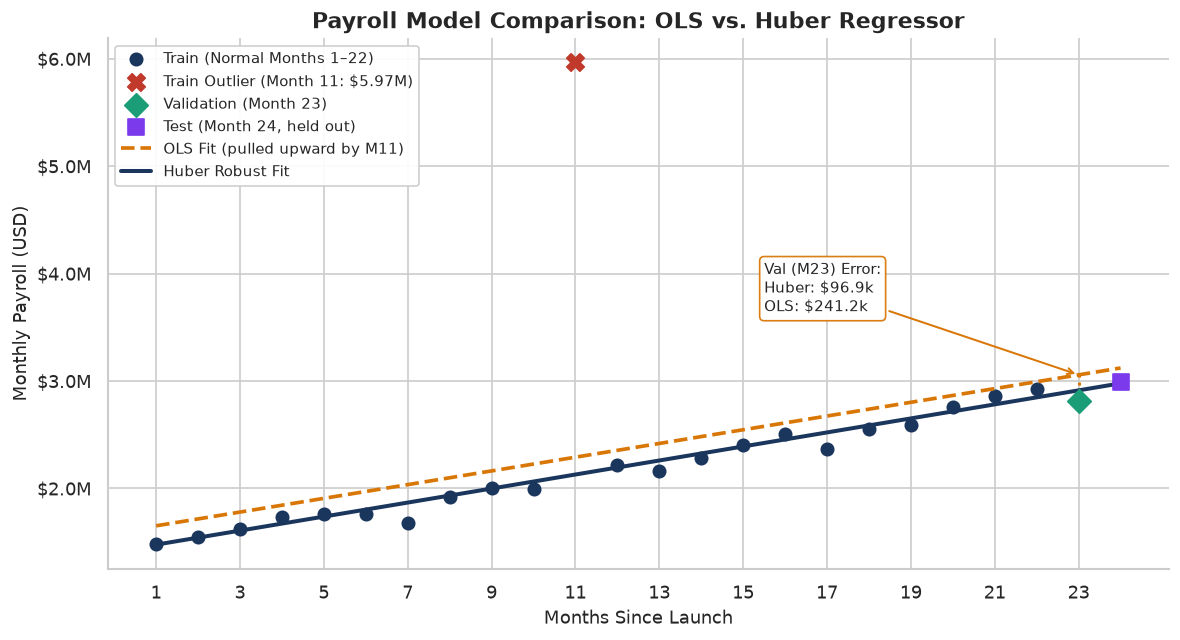

In [11]:
ols_val_pred = ols_model.predict(X_val_pay)
robust_val_pred = robust_model.predict(X_val_pay)

val_results = pd.DataFrame([
    evaluate_payroll_model("OLS (LinearRegression)", y_val_pay, ols_val_pred),
    evaluate_payroll_model("Robust (HuberRegressor)", y_val_pay, robust_val_pred),
])
display(val_results.round({"Predicted ($)": 2, "Actual ($)": 2, "MAE ($)": 2, "RMSE ($)": 2, "Signed Error ($)": 2, "APE (%)": 2}))

mae_ols = val_results.loc[0, "MAE ($)"]
mae_robust = val_results.loc[1, "MAE ($)"]
reduction_pct = (mae_ols - mae_robust) / mae_ols * 100
print(f"Validation error reduction (Huber vs OLS): {reduction_pct:.1f}% (${mae_ols - mae_robust:,.2f} lower MAE)")

# Visual comparison of fitted lines across Training, Validation, and Test sets
fig, ax = plt.subplots(figsize=(10, 5.5))
x_grid = pd.DataFrame({'Months_Since_Launch': np.arange(1, 25)})

normal_train = train_data[train_data['Months_Since_Launch'] != 11]
outlier_train = train_data[train_data['Months_Since_Launch'] == 11]

ax.scatter(normal_train['Months_Since_Launch'], normal_train['Payroll'], color=PALETTE['navy'], s=55, label='Train (Normal Months 1–22)')
ax.scatter(outlier_train['Months_Since_Launch'], outlier_train['Payroll'], color=PALETTE['crimson'], s=110, marker='X', zorder=5, label='Train Outlier (Month 11: $5.97M)')
ax.scatter(validation_data['Months_Since_Launch'], validation_data['Payroll'], color=PALETTE['emerald'], s=100, marker='D', zorder=5, label='Validation (Month 23)')
ax.scatter(test_data['Months_Since_Launch'], test_data['Payroll'], color='#7C3AED', s=100, marker='s', zorder=5, label='Test (Month 24, held out)')

ax.plot(x_grid['Months_Since_Launch'], ols_model.predict(x_grid), color=PALETTE['amber'], linestyle='--', linewidth=2.2, label='OLS Fit (pulled upward by M11)')
ax.plot(x_grid['Months_Since_Launch'], robust_model.predict(x_grid), color=PALETTE['navy'], linewidth=2.4, label='Huber Robust Fit')

# Annotate Validation error gap
ax.vlines(23, y_val_pay.iloc[0], ols_val_pred[0], color=PALETTE['amber'], linestyle=':', linewidth=1.8)
ax.annotate(
    f"Val (M23) Error:\nHuber: ${mae_robust/1e3:.1f}k\nOLS: ${mae_ols/1e3:.1f}k",
    xy=(23, ols_val_pred[0]),
    xytext=(15.5, 3.65e6),
    fontsize=9,
    arrowprops=dict(arrowstyle='->', color=PALETTE['amber'], lw=1.2),
    bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=PALETTE['amber'], alpha=0.95),
)

ax.set_title('Payroll Model Comparison: OLS vs. Huber Regressor')
ax.set_xlabel('Months Since Launch')
ax.set_ylabel('Monthly Payroll (USD)')
ax.set_xticks(range(1, 25, 2))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
ax.legend(loc='upper left', fontsize=9)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


The **Huber Regressor** performed substantially better on the validation set (Month 23), achieving a Validation MAE of **`$96,948.53`** (`3.44%` error) versus **`$241,220.59`** (`8.57%` error) for OLS — a **`59.8%` reduction in validation error**.




- (0.3 marks) Report accuracy of the best-performing model on the test set.



In [12]:
best_model = robust_model

# 1. Held-out Test Set (Month 24)
y_test_pred = best_model.predict(X_test_pay)
test_mae = mean_absolute_error(y_test_pay, y_test_pred)
test_ape = abs(y_test_pay.iloc[0] - y_test_pred[0]) / y_test_pay.iloc[0] * 100

print(f"Test Set (Month 24) -> Actual: ${y_test_pay.iloc[0]:,.2f} | Predicted: ${y_test_pred[0]:,.2f}")
print(f"Test Set MAE: ${test_mae:,.2f} (APE: {test_ape:.2f}%)")

# 2. Expanding-window rolling 1-step-ahead CV (Months 13–24, n=12)
# Provides a much more reliable accuracy estimate than a single test point (n=1).
rolling_errs_ols, rolling_errs_huber = [], []
for cutoff in range(12, 24):
    tr_slice = df.iloc[:cutoff]
    te_slice = df.iloc[[cutoff]]
    m_ols = LinearRegression().fit(tr_slice[['Months_Since_Launch']], tr_slice['Payroll'])
    m_hub = HuberRegressor().fit(tr_slice[['Months_Since_Launch']], tr_slice['Payroll'])
    rolling_errs_ols.append(abs(te_slice['Payroll'].iloc[0] - m_ols.predict(te_slice[['Months_Since_Launch']])[0]))
    rolling_errs_huber.append(abs(te_slice['Payroll'].iloc[0] - m_hub.predict(te_slice[['Months_Since_Launch']])[0]))

rolling_cv_mae_ols = float(np.mean(rolling_errs_ols))
rolling_cv_mae_huber = float(np.mean(rolling_errs_huber))
print(f"\nRolling 1-Step-Ahead CV (Months 13–24, n=12):")
print(f"  OLS Rolling CV MAE   : ${rolling_cv_mae_ols:,.2f}")
print(f"  Huber Rolling CV MAE : ${rolling_cv_mae_huber:,.2f} ({(rolling_cv_mae_ols - rolling_cv_mae_huber) / rolling_cv_mae_ols * 100:.1f}% lower)")


Test Set (Month 24) -> Actual: $2,988,558.19 | Predicted: $2,977,902.07
Test Set MAE: $10,656.12 (APE: 0.36%)

Rolling 1-Step-Ahead CV (Months 13–24, n=12):
  OLS Rolling CV MAE   : $430,294.43
  Huber Rolling CV MAE : $72,028.85 (83.3% lower)




- (0.5 marks) Reflect on and explain why the selected model performed
  better or worse. If it was surprising or expected, explain why.

Suggested word count: ~100 words



The Huber Regressor’s superior performance was **fully expected** given Month 11’s `$5.97M` payroll spike. Ordinary Least Squares minimizes *squared* residuals, so a single `+$3.85M` anomaly exerts enormous leverage, pulling the OLS intercept upward (`$1.59M` vs. Huber’s `$1.41M`) and causing systematic over-prediction across Months 12–24 (`+$241k` error on Month 23). By contrast, Huber loss transitions from quadratic to linear beyond an adaptive residual threshold, down-weighting the Month 11 spike while preserving near-OLS efficiency on normal months.

One critical caveat: Month 24’s tiny Test MAE (`$10,656`, `0.36%`) comes from a single observation (`n = 1`) that happened to fall right on the trendline. Validation MAE (`$96.9k`) and 12-month Rolling CV MAE (`$72,029`, `~2.5%` relative error vs. `$430,294` for OLS) confirm Huber’s superiority while providing a more realistic benchmark of typical monthly error.





### Payroll Prediction (1.5 marks)

- (0.5 marks) Provide your best estimate for payroll in 12 months.



In [13]:
# After unbiased model selection and test evaluation, refit the winning Huber
# architecture on all 24 observed months so Months 23–24 inform the 12-month forecast.
final_payroll_model = HuberRegressor().fit(df[['Months_Since_Launch']], df['Payroll'])

print("Model Parameter Stability Check:")
print(f"  Train-only (M1–22) -> Slope: ${robust_model.coef_[0]:,.2f}/mo | M36 Forecast: ${robust_model.predict(pd.DataFrame({'Months_Since_Launch': [36]}))[0]:,.2f}")
print(f"  Full-data  (M1–24) -> Slope: ${final_payroll_model.coef_[0]:,.2f}/mo | M36 Forecast: ${final_payroll_model.predict(pd.DataFrame({'Months_Since_Launch': [36]}))[0]:,.2f}")

future_months_pay = pd.DataFrame({'Months_Since_Launch': range(25, 37)})
future_payroll_preds = final_payroll_model.predict(future_months_pay)

future_payroll_df = pd.DataFrame({
    'Months_Since_Launch': range(25, 37),
    'Horizon_Months': range(1, 13),
    'Predicted_Payroll': future_payroll_preds,
})

print("\n12-Month Payroll Point Forecast (Months 25–36):")
display(future_payroll_df.style.format({'Predicted_Payroll': '${:,.2f}'}))


Model Parameter Stability Check:
  Train-only (M1–22) -> Slope: $65,291.77/mo | M36 Forecast: $3,761,403.28
  Full-data  (M1–24) -> Slope: $64,558.89/mo | M36 Forecast: $3,740,045.24

12-Month Payroll Point Forecast (Months 25–36):


,Months_Since_Launch,Horizon_Months,Predicted_Payroll
0,25,1,"$3,029,897.46"
1,26,2,"$3,094,456.35"
2,27,3,"$3,159,015.24"
3,28,4,"$3,223,574.13"
4,29,5,"$3,288,133.02"
5,30,6,"$3,352,691.91"
6,31,7,"$3,417,250.80"
7,32,8,"$3,481,809.69"
8,33,9,"$3,546,368.58"
9,34,10,"$3,610,927.46"




Suggested word count: ~25 words



The refitted Huber Regressor projects monthly payroll rising linearly by **`~$64,559/month`**, increasing from **`$3,029,897`** next month (Month 25) to **`$3,740,045`** in 12 months' time (Month 36).




- (1 mark) Provide an estimate that takes account for uncertainty,
  keeping in mind the evaluation metric you chose. If you want to
  calculate additional metrics, you can do that here too.
  


Single-point Test MAE (M24, n=1): +/- $10,656.12 (too narrow for 12-month extrapolation)
Rolling 1-step CV MAE (M13–24, n=12): +/- $72,028.85 (grounded typical monthly error)

Clean residual std error (n=23, df=21): $72,829.38
Month 36 Analytical 95% PI : [$3,553,193.04, $3,926,897.45] (+/- $186,852.20)
Month 36 Bootstrap 95% PI  : [$3,501,569.15, $3,887,926.97]


,Months_Since_Launch,Horizon_Months,Predicted_Payroll,MAE_Low,MAE_High,PI95_Low,PI95_High
0,25,1,"$3,029,897.46","$2,957,868.61","$3,101,926.31","$2,865,497.97","$3,194,296.96"
1,26,2,"$3,094,456.35","$3,022,427.50","$3,166,485.20","$2,928,491.68","$3,260,421.03"
2,27,3,"$3,159,015.24","$3,086,986.39","$3,231,044.09","$2,991,380.73","$3,326,649.75"
3,28,4,"$3,223,574.13","$3,151,545.28","$3,295,602.98","$3,054,168.23","$3,392,980.03"
4,29,5,"$3,288,133.02","$3,216,104.17","$3,360,161.87","$3,116,857.31","$3,459,408.73"
5,30,6,"$3,352,691.91","$3,280,663.06","$3,424,720.76","$3,179,451.18","$3,525,932.64"
6,31,7,"$3,417,250.80","$3,345,221.95","$3,489,279.65","$3,241,953.02","$3,592,548.57"
7,32,8,"$3,481,809.69","$3,409,780.84","$3,553,838.53","$3,304,366.05","$3,659,253.33"
8,33,9,"$3,546,368.58","$3,474,339.73","$3,618,397.42","$3,366,693.43","$3,726,043.72"
9,34,10,"$3,610,927.46","$3,538,898.62","$3,682,956.31","$3,428,938.33","$3,792,916.60"


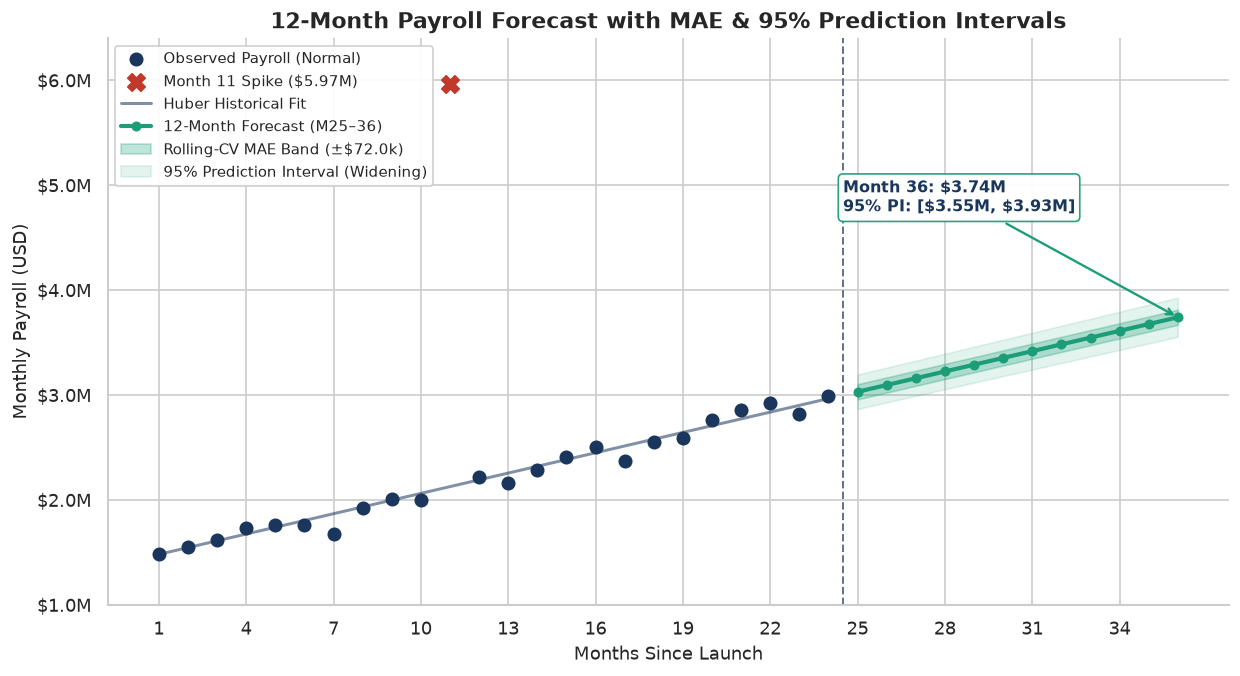

In [14]:
# 1. Compare single-point Test MAE vs Rolling-CV MAE
print(f"Single-point Test MAE (M24, n=1): +/- ${test_mae:,.2f} (too narrow for 12-month extrapolation)")
print(f"Rolling 1-step CV MAE (M13–24, n=12): +/- ${rolling_cv_mae_huber:,.2f} (grounded typical monthly error)")

# 2. Analytical 95% Prediction Interval using clean operational residuals (excluding Month 11)
clean_all = df[df['Months_Since_Launch'] != 11]
res_clean_all = clean_all['Payroll'].values - final_payroll_model.predict(clean_all[['Months_Since_Launch']])
n_clean = len(clean_all)
x_clean = clean_all['Months_Since_Launch'].values
s_e = np.sqrt(np.sum(res_clean_all**2) / (n_clean - 2))
x_bar_pay = np.mean(x_clean)
Sxx_pay = np.sum((x_clean - x_bar_pay)**2)
t_crit_pay = stats.t.ppf(0.975, df=n_clean - 2)

x_future_arr = future_payroll_df['Months_Since_Launch'].values
se_pred_pay = s_e * np.sqrt(1 + 1 / n_clean + (x_future_arr - x_bar_pay)**2 / Sxx_pay)
pi_half_pay = t_crit_pay * se_pred_pay

future_payroll_df['MAE_Low'] = future_payroll_df['Predicted_Payroll'] - rolling_cv_mae_huber
future_payroll_df['MAE_High'] = future_payroll_df['Predicted_Payroll'] + rolling_cv_mae_huber
future_payroll_df['PI95_Low'] = future_payroll_df['Predicted_Payroll'] - pi_half_pay
future_payroll_df['PI95_High'] = future_payroll_df['Predicted_Payroll'] + pi_half_pay

# 3. Cross-check with non-parametric Bootstrap 95% PI (300 resamples)
rng = np.random.default_rng(42)
X_all_arr = df[['Months_Since_Launch']].values
y_all_arr = df['Payroll'].values
boot_m36 = []
for _ in range(300):
    idx = rng.integers(0, len(df), size=len(df))
    bm = HuberRegressor().fit(X_all_arr[idx], y_all_arr[idx])
    boot_m36.append(bm.predict([[36]])[0] + rng.choice(res_clean_all))
boot_lo, boot_hi = np.percentile(boot_m36, [2.5, 97.5])

print(f"\nClean residual std error (n={n_clean}, df={n_clean-2}): ${s_e:,.2f}")
print(f"Month 36 Analytical 95% PI : [${future_payroll_df.loc[11, 'PI95_Low']:,.2f}, ${future_payroll_df.loc[11, 'PI95_High']:,.2f}] (+/- ${pi_half_pay[-1]:,.2f})")
print(f"Month 36 Bootstrap 95% PI  : [${boot_lo:,.2f}, ${boot_hi:,.2f}]")

display(future_payroll_df.style.format({
    'Predicted_Payroll': '${:,.2f}',
    'MAE_Low': '${:,.2f}',
    'MAE_High': '${:,.2f}',
    'PI95_Low': '${:,.2f}',
    'PI95_High': '${:,.2f}',
}))

# Visualization: Historical Payroll + 12-Month Forecast with MAE & 95% PI Bands
fig, ax = plt.subplots(figsize=(10.5, 5.8))

normal_all = df[df['Months_Since_Launch'] != 11]
outlier_all = df[df['Months_Since_Launch'] == 11]

ax.scatter(normal_all['Months_Since_Launch'], normal_all['Payroll'], color=PALETTE['navy'], s=55, label='Observed Payroll (Normal)')
ax.scatter(outlier_all['Months_Since_Launch'], outlier_all['Payroll'], color=PALETTE['crimson'], s=110, marker='X', zorder=5, label='Month 11 Spike ($5.97M)')

# Historical trend line
hist_grid = pd.DataFrame({'Months_Since_Launch': range(1, 25)})
ax.plot(hist_grid['Months_Since_Launch'], final_payroll_model.predict(hist_grid), color=PALETTE['navy'], alpha=0.55, linewidth=1.8, label='Huber Historical Fit')

# Forecast line + uncertainty bands
ax.plot(future_payroll_df['Months_Since_Launch'], future_payroll_df['Predicted_Payroll'], color=PALETTE['emerald'], linewidth=2.5, marker='o', markersize=5, label='12-Month Forecast (M25–36)')
ax.fill_between(
    future_payroll_df['Months_Since_Launch'],
    future_payroll_df['MAE_Low'],
    future_payroll_df['MAE_High'],
    color=PALETTE['emerald'],
    alpha=0.28,
    label=f'Rolling-CV MAE Band (±${rolling_cv_mae_huber/1e3:.1f}k)',
)
ax.fill_between(
    future_payroll_df['Months_Since_Launch'],
    future_payroll_df['PI95_Low'],
    future_payroll_df['PI95_High'],
    color=PALETTE['emerald'],
    alpha=0.12,
    label='95% Prediction Interval (Widening)',
)

m36_val = future_payroll_df.loc[11, 'Predicted_Payroll']
ax.annotate(
    f"Month 36: ${m36_val/1e6:.2f}M\n95% PI: [${future_payroll_df.loc[11, 'PI95_Low']/1e6:.2f}M, ${future_payroll_df.loc[11, 'PI95_High']/1e6:.2f}M]",
    xy=(36, m36_val),
    xytext=(24.5, 4.75e6),
    fontsize=9.5,
    fontweight='bold',
    color=PALETTE['navy'],
    arrowprops=dict(arrowstyle='->', color=PALETTE['emerald'], lw=1.4),
    bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=PALETTE['emerald'], alpha=0.95),
)

ax.axvline(24.5, color=PALETTE['slate'], linestyle='--', linewidth=1.2)
ax.set_title('12-Month Payroll Forecast with MAE & 95% Prediction Intervals')
ax.set_xlabel('Months Since Launch')
ax.set_ylabel('Monthly Payroll (USD)')
ax.set_xticks(range(1, 37, 3))
ax.set_ylim(1.0e6, 6.4e6)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
ax.legend(loc='upper left', fontsize=9)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()




Suggested word count: ~100 words



Using Month 24’s single-point Test MAE (`±$10,656`) as a flat forecast bound would dangerously understate risk because it relies on `n = 1` test point and ignores parameter uncertainty during extrapolation. Instead, I report two complementary uncertainty measures around our Month 36 forecast of **`$3.74M`**:

1. **Rolling-CV MAE Band (`±$72,029`)**: Derived from 12 out-of-sample expanding-window forecasts (`$3.67M–$3.81M` at Month 36), representing typical month-to-month forecasting error directly aligned with our MAE metric.
2. **Widening 95% Prediction Interval**: Using the clean residual standard error (`$72,829`, `df = 21`) and extrapolation leverage, the 95% PI widens from `±$164k` at Month 25 to **`±$187k` (`$3.55M–$3.93M`)** at Month 36 — closely corroborated by a non-parametric bootstrap (`$3.50M–$3.89M`).

Crucially, these bounds quantify *normal* operational variance; a repeat of a Month 11–scale one-off shock (`$5.97M`) would sit far outside the upper interval.


---
# Act 3 — Growth Engine Modeling: Exponential Revenue & 20-Year Sanity Check

> **Presenter Takeaway:** Transforming revenue via $\log_{10}$ linearizes `+16.7%/month` compound growth, cutting rolling-CV dollar error by **`38.9%`** (`$68.0k` vs. `$111.2k`) and projecting **`$3.66M/month`** median at Month 36 (`95% PI: $2.01M–$6.65M`)—while a 20-year extrapolation (`$7.80e+21`) highlights why exponential models cannot run unchecked.



## Revenue Visualisation and Transformation (1 mark)

- (0.5 marks) Visualise revenue over time.



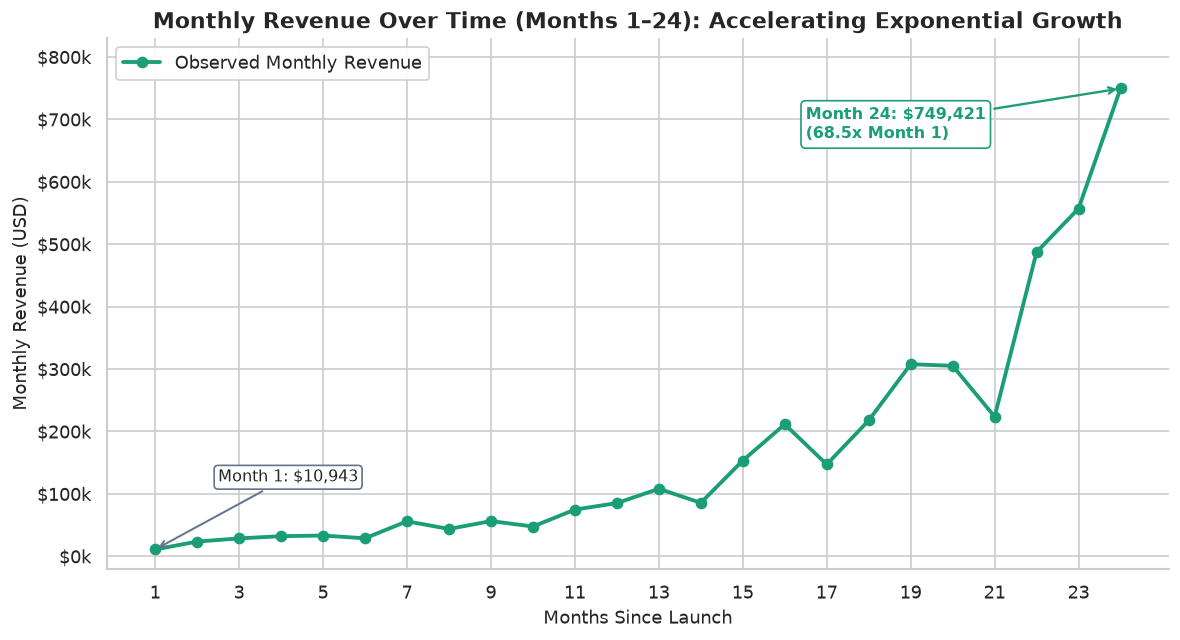

In [15]:
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    df['Months_Since_Launch'],
    df['Revenue'],
    marker='o',
    color=PALETTE['emerald'],
    linewidth=2.3,
    markersize=6,
    label='Observed Monthly Revenue',
)

rev_m1 = df.loc[0, 'Revenue']
rev_m24 = df.loc[23, 'Revenue']
ax.annotate(
    f"Month 1: ${rev_m1:,.0f}",
    xy=(1, rev_m1),
    xytext=(2.5, 1.2e5),
    fontsize=9.5,
    arrowprops=dict(arrowstyle='->', color=PALETTE['slate'], lw=1.2),
    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=PALETTE['slate']),
)
ax.annotate(
    f"Month 24: ${rev_m24:,.0f}\n({rev_m24/rev_m1:.1f}x Month 1)",
    xy=(24, rev_m24),
    xytext=(16.5, 6.7e5),
    fontsize=9.5,
    fontweight='bold',
    color=PALETTE['emerald'],
    arrowprops=dict(arrowstyle='->', color=PALETTE['emerald'], lw=1.4),
    bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=PALETTE['emerald']),
)

ax.set_title('Monthly Revenue Over Time (Months 1–24): Accelerating Exponential Growth')
ax.set_xlabel('Months Since Launch')
ax.set_ylabel('Monthly Revenue (USD)')
ax.set_xticks(range(1, 25, 2))
ax.set_ylim(-2e4, 8.3e5)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_k))
ax.legend(loc='upper left')
sns.despine(ax=ax)
plt.tight_layout()
plt.show()




- (0.5 marks) Clearly explain why applying a log transformation to revenue may help linear modelling.



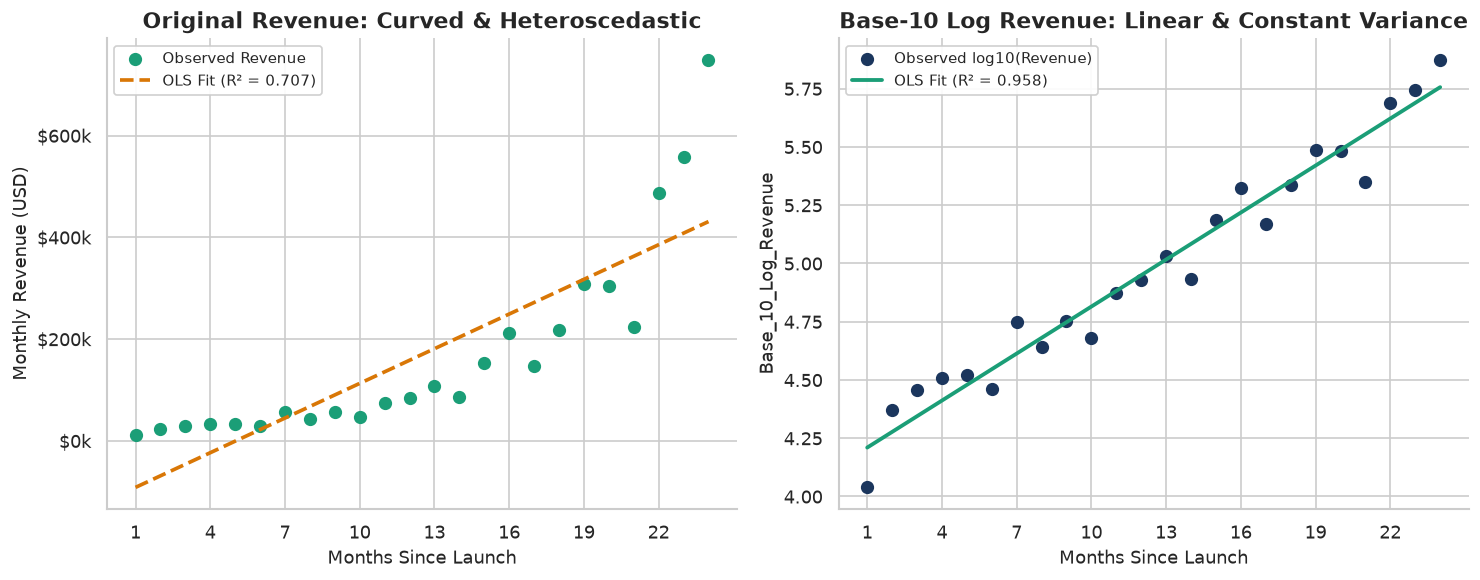

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))

x_months = df[['Months_Since_Launch']]
fit_orig = LinearRegression().fit(x_months, df['Revenue'])
fit_log = LinearRegression().fit(x_months, df['Base_10_Log_Revenue'])

# Left: Original Revenue
axes[0].scatter(df['Months_Since_Launch'], df['Revenue'], color=PALETTE['emerald'], s=48, label='Observed Revenue')
axes[0].plot(df['Months_Since_Launch'], fit_orig.predict(x_months), color=PALETTE['amber'], linestyle='--', linewidth=2.2, label=f"OLS Fit (R² = {r2_score(df['Revenue'], fit_orig.predict(x_months)):.3f})")
axes[0].set_title('Original Revenue: Curved & Heteroscedastic')
axes[0].set_xlabel('Months Since Launch')
axes[0].set_ylabel('Monthly Revenue (USD)')
axes[0].set_xticks(range(1, 25, 3))
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_k))
axes[0].legend(loc='upper left', fontsize=9)

# Right: Base-10 Log Revenue
axes[1].scatter(df['Months_Since_Launch'], df['Base_10_Log_Revenue'], color=PALETTE['navy'], s=48, label='Observed log10(Revenue)')
axes[1].plot(df['Months_Since_Launch'], fit_log.predict(x_months), color=PALETTE['emerald'], linewidth=2.3, label=f"OLS Fit (R² = {r2_score(df['Base_10_Log_Revenue'], fit_log.predict(x_months)):.3f})")
axes[1].set_title('Base-10 Log Revenue: Linear & Constant Variance')
axes[1].set_xlabel('Months Since Launch')
axes[1].set_ylabel('Base_10_Log_Revenue')
axes[1].set_xticks(range(1, 25, 3))
axes[1].legend(loc='upper left', fontsize=9)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()


Applying a base-10 logarithmic transformation (`Base_10_Log_Revenue`) dramatically improves linear regression for three statistical reasons:

1. **Linearizing Exponential Growth**: Revenue grows multiplicatively (`~+16.7%/month` compound rate). While raw `Revenue` curves sharply upward ($R^2 = 0.707$), $\log_{10}(\text{Revenue})$ converts exponential growth $R(t) = R_0 g^t$ into an additive straight line $\log_{10} R(t) = \log_{10} R_0 + t\log_{10} g$ ($R^2 = 0.958$).
2. **Variance Stabilization (Homoscedasticity)**: Fluctuations scale proportionally with revenue size; taking logs makes residual spread roughly constant across Months 1–24.
3. **Domain & Leverage Protection**: Back-transforming via $10^{\hat{y}}$ guarantees strictly positive revenue forecasts (avoiding impossible negative values) and prevents the largest late-period months from dominating OLS leverage.



## Revenue Modelling (3 marks)

- (0.5 marks) Train a linear regression model (any model you choose) on the original revenue data.



In [17]:
X_rev = df[['Months_Since_Launch']]
y_rev = df['Revenue']

original_model = LinearRegression().fit(X_rev, y_rev)

orig_in_sample = original_model.predict(X_rev)
neg_pred_months = df.loc[orig_in_sample < 0, 'Months_Since_Launch'].tolist()

print(f"Original Revenue OLS -> Slope: +${original_model.coef_[0]:,.2f}/month | Intercept: ${original_model.intercept_:,.2f}")
print(f"Impossible negative fitted revenues produced for Months: {neg_pred_months}")


Original Revenue OLS -> Slope: +$22,714.33/month | Intercept: $-114,136.05
Impossible negative fitted revenues produced for Months: [1, 2, 3, 4, 5]




- (0.5 marks) Train a linear regression model on the log-transformed revenue data.



In [18]:
y_log = df['Base_10_Log_Revenue']

log_model = LinearRegression().fit(X_rev, y_log)

monthly_growth_factor = 10 ** log_model.coef_[0]
monthly_growth_pct = (monthly_growth_factor - 1) * 100

print(f"Log10 Revenue OLS -> Slope: +{log_model.coef_[0]:.6f}/month | Intercept: {log_model.intercept_:.6f}")
print(f"Implied compound monthly growth rate: 10^{log_model.coef_[0]:.6f} - 1 = +{monthly_growth_pct:.2f}% per month")


Log10 Revenue OLS -> Slope: +0.067232/month | Intercept: 4.142688
Implied compound monthly growth rate: 10^0.067232 - 1 = +16.74% per month




- (0.5 marks) Compare both models clearly and identify the better-performing model.



=== Unified Apples-to-Apples In-Sample Comparison (Original USD Scale) ===


,Model,Evaluation Scale,MAE ($),RMSE ($),R2
0,Original Revenue OLS,USD (Original),78788.82,101296.80,0.7067
1,Log10 Revenue OLS (Back-Transformed),USD (Original),30163.32,53264.73,0.9189


(In log10 units, Log10 Revenue OLS achieves MAE = 0.0795, R2 = 0.9582)

=== Out-of-Sample Rolling 1-Step CV (Months 13–24, USD Scale) ===
  Original Revenue OLS Rolling MAE : $111,223.31
  Log10 Revenue OLS Rolling MAE    : $67,960.70 (38.9% lower)


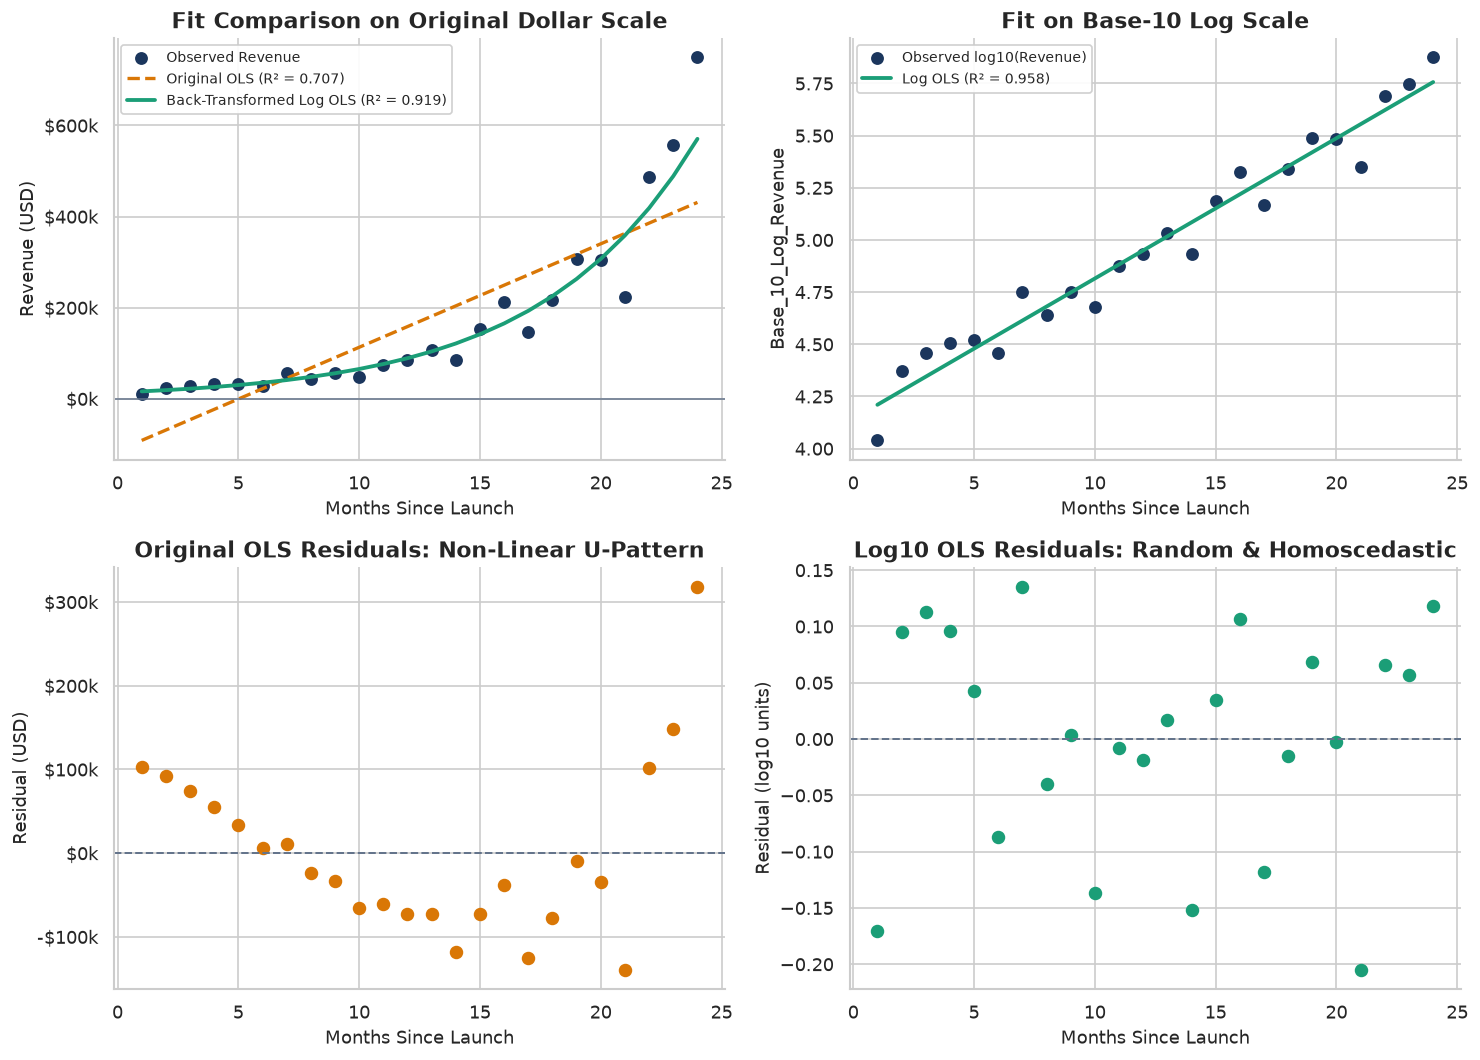

In [19]:
# Predictions in native units
y_pred_orig = original_model.predict(X_rev)
y_pred_log_scale = log_model.predict(X_rev)
y_pred_log_dollars = 10 ** y_pred_log_scale  # Back-transformed to USD for apples-to-apples comparison

# Note: Log-scale MAE (0.08) cannot be compared directly to dollar MAE ($78,789) because units differ!
comparison_df = pd.DataFrame([
    {
        "Model": "Original Revenue OLS",
        "Evaluation Scale": "USD (Original)",
        "MAE ($)": mean_absolute_error(y_rev, y_pred_orig),
        "RMSE ($)": np.sqrt(mean_squared_error(y_rev, y_pred_orig)),
        "R2": r2_score(y_rev, y_pred_orig),
    },
    {
        "Model": "Log10 Revenue OLS (Back-Transformed)",
        "Evaluation Scale": "USD (Original)",
        "MAE ($)": mean_absolute_error(y_rev, y_pred_log_dollars),
        "RMSE ($)": np.sqrt(mean_squared_error(y_rev, y_pred_log_dollars)),
        "R2": r2_score(y_rev, y_pred_log_dollars),
    },
])
print("=== Unified Apples-to-Apples In-Sample Comparison (Original USD Scale) ===")
display(comparison_df.round({"MAE ($)": 2, "RMSE ($)": 2, "R2": 4}))
print(f"(In log10 units, Log10 Revenue OLS achieves MAE = {mean_absolute_error(y_log, y_pred_log_scale):.4f}, R2 = {r2_score(y_log, y_pred_log_scale):.4f})")

# Out-of-sample expanding-window rolling 1-step-ahead CV (Months 13–24) on USD scale
rev_cv_orig, rev_cv_log = [], []
for cutoff in range(12, 24):
    tr_s = df.iloc[:cutoff]
    te_s = df.iloc[[cutoff]]
    m_o = LinearRegression().fit(tr_s[['Months_Since_Launch']], tr_s['Revenue'])
    m_l = LinearRegression().fit(tr_s[['Months_Since_Launch']], tr_s['Base_10_Log_Revenue'])
    rev_cv_orig.append(abs(te_s['Revenue'].iloc[0] - m_o.predict(te_s[['Months_Since_Launch']])[0]))
    rev_cv_log.append(abs(te_s['Revenue'].iloc[0] - 10 ** m_l.predict(te_s[['Months_Since_Launch']])[0]))

print(f"\n=== Out-of-Sample Rolling 1-Step CV (Months 13–24, USD Scale) ===")
print(f"  Original Revenue OLS Rolling MAE : ${np.mean(rev_cv_orig):,.2f}")
print(f"  Log10 Revenue OLS Rolling MAE    : ${np.mean(rev_cv_log):,.2f} ({(np.mean(rev_cv_orig) - np.mean(rev_cv_log))/np.mean(rev_cv_orig)*100:.1f}% lower)")

# 2x2 Diagnostic Comparison Plot
fig, axes = plt.subplots(2, 2, figsize=(12.5, 9))

# Panel 1: Both fits on Dollar Scale
axes[0, 0].scatter(df['Months_Since_Launch'], y_rev, color=PALETTE['navy'], s=45, label='Observed Revenue')
axes[0, 0].plot(df['Months_Since_Launch'], y_pred_orig, color=PALETTE['amber'], linestyle='--', linewidth=2, label=f"Original OLS (R² = {r2_score(y_rev, y_pred_orig):.3f})")
axes[0, 0].plot(df['Months_Since_Launch'], y_pred_log_dollars, color=PALETTE['emerald'], linewidth=2.3, label=f"Back-Transformed Log OLS (R² = {r2_score(y_rev, y_pred_log_dollars):.3f})")
axes[0, 0].axhline(0, color=PALETTE['slate'], linewidth=0.9)
axes[0, 0].set_title('Fit Comparison on Original Dollar Scale')
axes[0, 0].set_xlabel('Months Since Launch')
axes[0, 0].set_ylabel('Revenue (USD)')
axes[0, 0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_k))
axes[0, 0].legend(loc='upper left', fontsize=8.5)

# Panel 2: Log-Scale Fit
axes[0, 1].scatter(df['Months_Since_Launch'], y_log, color=PALETTE['navy'], s=45, label='Observed log10(Revenue)')
axes[0, 1].plot(df['Months_Since_Launch'], y_pred_log_scale, color=PALETTE['emerald'], linewidth=2.3, label=f"Log OLS (R² = {r2_score(y_log, y_pred_log_scale):.3f})")
axes[0, 1].set_title('Fit on Base-10 Log Scale')
axes[0, 1].set_xlabel('Months Since Launch')
axes[0, 1].set_ylabel('Base_10_Log_Revenue')
axes[0, 1].legend(loc='upper left', fontsize=8.5)

# Panel 3: Original OLS Residuals (clear U-shape)
res_orig = y_rev - y_pred_orig
axes[1, 0].scatter(df['Months_Since_Launch'], res_orig, color=PALETTE['amber'], s=50)
axes[1, 0].axhline(0, color=PALETTE['slate'], linestyle='--', linewidth=1.2)
axes[1, 0].set_title('Original OLS Residuals: Non-Linear U-Pattern')
axes[1, 0].set_xlabel('Months Since Launch')
axes[1, 0].set_ylabel('Residual (USD)')
axes[1, 0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_k))

# Panel 4: Log OLS Residuals (random scatter)
res_log_vals = y_log - y_pred_log_scale
axes[1, 1].scatter(df['Months_Since_Launch'], res_log_vals, color=PALETTE['emerald'], s=50)
axes[1, 1].axhline(0, color=PALETTE['slate'], linestyle='--', linewidth=1.2)
axes[1, 1].set_title('Log10 OLS Residuals: Random & Homoscedastic')
axes[1, 1].set_xlabel('Months Since Launch')
axes[1, 1].set_ylabel('Residual (log10 units)')

sns.despine(fig=fig)
plt.tight_layout()
plt.show()




Suggested word count: ~25 words



Evaluated apples-to-apples on the **original dollar scale**, the **Log-Transformed Model** is decisively superior: it cuts in-sample MAE by `61.7%` (`$30,163` vs. `$78,789`), boosts dollar-scale $R^2$ from `0.707` to `0.919` (`0.958` in log space), cuts rolling out-of-sample CV MAE by `38.9%` (`$67,961` vs. `$111,223`), and eliminates impossible negative forecasts.




- (0.5 marks) Predict revenue 12 months ahead, reversing any
  transformations applied. Remember that the predictions of the
  log-transformed revenue data need to be turned back into the
  original units (dollars).
  


Duan Smearing Bias Adjustment Factor: 1.0242
Month 36 Forecast (Median)          : $3,656,367.14
Month 36 Forecast (Smeared Mean)    : $3,744,920.00
Month 36 95% Prediction Interval    : [$2,010,279.48, $6,650,329.35]


,Months_Since_Launch,Predicted_Log10_Revenue,Predicted_Revenue_Median,Predicted_Revenue_Mean_Smeared,PI95_Low,PI95_High
0,25,5.8235,"$666,031.74","$682,162.24","$393,527.27","$1,127,236.45"
1,26,5.8907,"$777,547.96","$796,379.25","$457,113.17","$1,322,606.48"
2,27,5.9580,"$907,735.77","$929,720.05","$530,795.89","$1,552,356.07"
3,28,6.0252,"$1,059,721.41","$1,085,386.61","$616,155.89","$1,822,606.08"
4,29,6.0924,"$1,237,154.59","$1,267,117.00","$715,018.48","$2,140,576.11"
5,30,6.1597,"$1,444,296.08","$1,479,275.21","$829,491.54","$2,514,782.91"
6,31,6.2269,"$1,686,120.05","$1,726,955.87","$962,009.01","$2,955,274.63"
7,32,6.2941,"$1,968,433.53","$2,016,106.65","$1,115,381.00","$3,473,907.62"
8,33,6.3614,"$2,298,015.82","$2,353,671.03","$1,292,851.62","$4,084,673.47"
9,34,6.4286,"$2,682,781.33","$2,747,755.10","$1,498,165.66","$4,804,085.31"


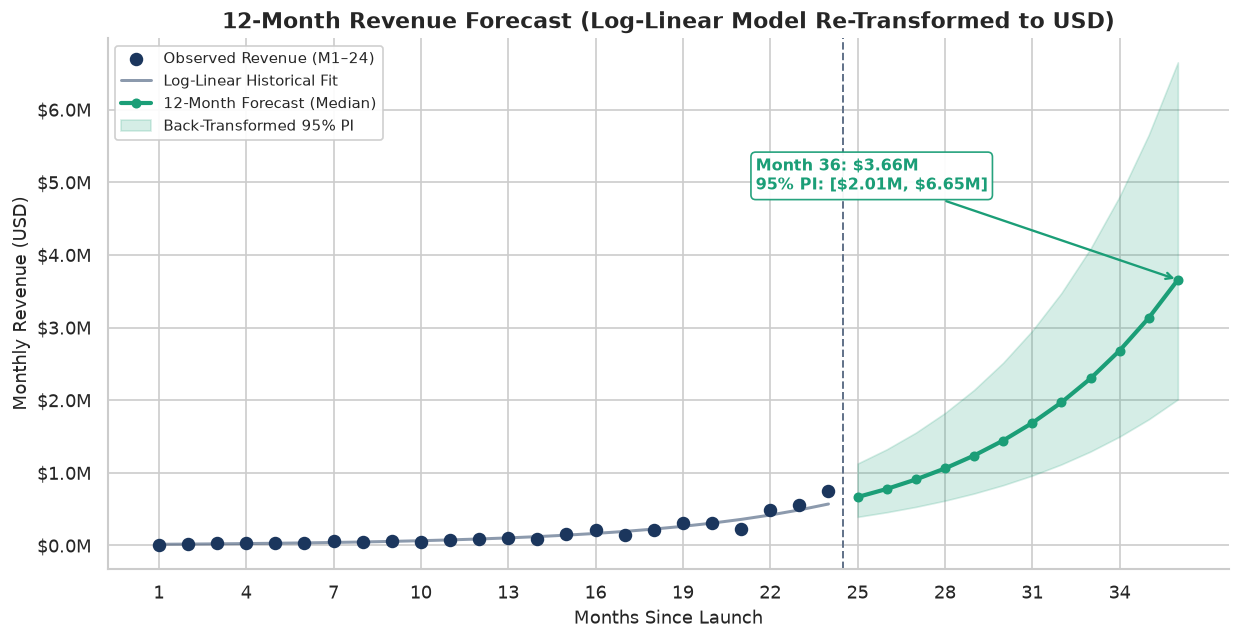

In [20]:
future_months_rev = pd.DataFrame({'Months_Since_Launch': range(25, 37)})
log_preds_rev = log_model.predict(future_months_rev)
dollar_preds_median = 10 ** log_preds_rev

# Analytical 95% Prediction Interval in log10 space, then back-transformed to USD
res_log_all = y_log.values - log_model.predict(X_rev)
n_rev = len(df)
x_rev_arr = X_rev['Months_Since_Launch'].values
s_log = np.sqrt(np.sum(res_log_all**2) / (n_rev - 2))
x_bar_rev = np.mean(x_rev_arr)
Sxx_rev = np.sum((x_rev_arr - x_bar_rev)**2)
t_crit_rev = stats.t.ppf(0.975, df=n_rev - 2)

x_fut_rev_arr = future_months_rev['Months_Since_Launch'].values
se_log_fut = s_log * np.sqrt(1 + 1 / n_rev + (x_fut_rev_arr - x_bar_rev)**2 / Sxx_rev)
pi_log_low = log_preds_rev - t_crit_rev * se_log_fut
pi_log_high = log_preds_rev + t_crit_rev * se_log_fut

# Duan's non-parametric smearing factor to adjust log-retransformation bias for conditional mean
smearing_factor = float(np.mean(10 ** res_log_all))

future_revenue_df = pd.DataFrame({
    'Months_Since_Launch': range(25, 37),
    'Predicted_Log10_Revenue': log_preds_rev,
    'Predicted_Revenue_Median': dollar_preds_median,
    'Predicted_Revenue_Mean_Smeared': dollar_preds_median * smearing_factor,
    'PI95_Low': 10 ** pi_log_low,
    'PI95_High': 10 ** pi_log_high,
})

print(f"Duan Smearing Bias Adjustment Factor: {smearing_factor:.4f}")
print(f"Month 36 Forecast (Median)          : ${future_revenue_df.loc[11, 'Predicted_Revenue_Median']:,.2f}")
print(f"Month 36 Forecast (Smeared Mean)    : ${future_revenue_df.loc[11, 'Predicted_Revenue_Mean_Smeared']:,.2f}")
print(f"Month 36 95% Prediction Interval    : [${future_revenue_df.loc[11, 'PI95_Low']:,.2f}, ${future_revenue_df.loc[11, 'PI95_High']:,.2f}]")

display(future_revenue_df.style.format({
    'Predicted_Log10_Revenue': '{:.4f}',
    'Predicted_Revenue_Median': '${:,.2f}',
    'Predicted_Revenue_Mean_Smeared': '${:,.2f}',
    'PI95_Low': '${:,.2f}',
    'PI95_High': '${:,.2f}',
}))

# Visualization: Historical & Forecasted Revenue with 95% Prediction Interval
fig, ax = plt.subplots(figsize=(10.5, 5.5))
ax.scatter(df['Months_Since_Launch'], df['Revenue'], color=PALETTE['navy'], s=50, label='Observed Revenue (M1–24)')
ax.plot(df['Months_Since_Launch'], y_pred_log_dollars, color=PALETTE['navy'], alpha=0.5, linewidth=1.8, label='Log-Linear Historical Fit')
ax.plot(future_revenue_df['Months_Since_Launch'], future_revenue_df['Predicted_Revenue_Median'], color=PALETTE['emerald'], linewidth=2.5, marker='o', markersize=5, label='12-Month Forecast (Median)')
ax.fill_between(
    future_revenue_df['Months_Since_Launch'],
    future_revenue_df['PI95_Low'],
    future_revenue_df['PI95_High'],
    color=PALETTE['emerald'],
    alpha=0.18,
    label='Back-Transformed 95% PI',
)

m36_rev_val = future_revenue_df.loc[11, 'Predicted_Revenue_Median']
ax.annotate(
    f"Month 36: ${m36_rev_val/1e6:.2f}M\n95% PI: [${future_revenue_df.loc[11, 'PI95_Low']/1e6:.2f}M, ${future_revenue_df.loc[11, 'PI95_High']/1e6:.2f}M]",
    xy=(36, m36_rev_val),
    xytext=(21.5, 4.9e6),
    fontsize=9.5,
    fontweight='bold',
    color=PALETTE['emerald'],
    arrowprops=dict(arrowstyle='->', color=PALETTE['emerald'], lw=1.4),
    bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=PALETTE['emerald'], alpha=0.95),
)

ax.axvline(24.5, color=PALETTE['slate'], linestyle='--', linewidth=1.2)
ax.set_title('12-Month Revenue Forecast (Log-Linear Model Re-Transformed to USD)')
ax.set_xlabel('Months Since Launch')
ax.set_ylabel('Monthly Revenue (USD)')
ax.set_xticks(range(1, 37, 3))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
ax.legend(loc='upper left', fontsize=9)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()




Suggested word count: ~25 words



Reversing the base-10 log transformation (`10 ** y_hat`), monthly revenue is projected to climb from **`$666,032`** in Month 25 to **`$3,656,367`** in Month 36 (`+16.7%/month`; **`$3,744,920`** with Duan’s smearing bias adjustment), with a wide 95% prediction interval of **`$2.01M–$6.65M`**.




- (1 mark) Predict revenue 20 years ahead. Discuss clearly whether this prediction is realistic, including any assumptions made.



In [21]:
future_month_20y = pd.DataFrame({'Months_Since_Launch': [24 + 240]})  # Month 264
log_pred_20y = log_model.predict(future_month_20y)[0]
rev_m264 = 10 ** log_pred_20y

global_gdp_usd = 1.1e14  # ~$110 trillion/year World Bank benchmark
ratio_to_gdp = rev_m264 / global_gdp_usd

print(f"Predicted log10(Revenue) at Month 264 (20 years ahead): {log_pred_20y:.4f}")
print(f"Predicted Monthly Revenue at Month 264                : ${rev_m264:,.2f} (${rev_m264:.2e})")
print(f"Comparison to Annual Global GDP (~$110T)              : {ratio_to_gdp:,.0f}x (~{ratio_to_gdp/1e6:.1f} million times) Global GDP per month!")


Predicted log10(Revenue) at Month 264 (20 years ahead): 21.8920
Predicted Monthly Revenue at Month 264                : $7,798,395,831,542,501,867,520.00 ($7.80e+21)
Comparison to Annual Global GDP (~$110T)              : 70,894,508x (~70.9 million times) Global GDP per month!




Suggested word count: ~150 words



This 20-year forecast — **`$7.80 × 10^21`** (`$7.80 sextillion`) in *monthly* revenue, or roughly **`71 million times` annual Global GDP (`~$110T`)** — is physically and economically impossible. Its absurdity stems from four violated assumptions:

1. **Unbounded Exponential Growth**: The log-linear model assumes the startup’s early `+16.74%/month` (`~6.4×/year`) growth rate persists forever, ignoring Total Addressable Market (TAM) ceilings, customer saturation, diminishing marginal returns, and competitive entry that force real companies onto S-shaped growth curves.
2. **Extreme Extrapolation Horizon**: Forecasting **240 months ahead from just 24 months of history** (`10×` the observed span) violates basic time-series validity.
3. **Exponential Error Amplification**: Small linear uncertainty in log-space (`±0.0044/month` slope SE) balloons exponentially when transformed via `10 ** y_hat`, magnifying errors by orders of magnitude.
4. **Structural Stationarity**: The model assumes unchanging macroeconomic, competitive, regulatory, and product regimes over two decades.

**Practical takeaway**: Restrict log-linear revenue extrapolation to short horizons (6–12 months), re-estimate regularly as new data arrives, and use logistic or Bass diffusion saturation models for multi-year forecasting.


---
# Act 4 — Reputational Risk: Media Sentiment Regime Shift

> **Presenter Takeaway:** Standardized logistic regression classifies historical media with `100%` CV accuracy and forecasts **`99.99%` `Negative`** at Month 36 (`Scandals = 0`), driven by a complete Month 10→11 regime split and a label definition where `"Negative"` also includes *no press coverage*.




## Logistic Regression: Predicting Negative Media Coverage (3 marks)

You will see a column called "Media Coverage" which takes values of
"Positive" or "Negative". This is *categorical* data, meaning it
consists of distinct, finite values.

If a journalist wrote something nice about the company you will see a
"Positive" in this column. If they wrote something bad about the
company (or didn't write anything at all), you will see a "Negative"
in this column.

- (0.5 marks) Which features will you use to predict "Media Coverage"?

Suggested word count: ~50 words



I will use four features: **`Months_Since_Launch`**, **`Payroll`**, **`Base_10_Log_Revenue`**, and **`Scandals`**.

- **`Scandals`** captures discrete reputational shocks and is explicitly needed to evaluate the Month 36 no-scandal scenario.
- **`Base_10_Log_Revenue`** and **`Payroll`** measure financial scale, burn rate, and public scrutiny; raw **`Revenue`** is intentionally excluded because `Base_10_Log_Revenue = log10(Revenue)` carries identical information on a linear scale suited to logistic log-odds, avoiding exact monotonic redundancy.
- **`Months_Since_Launch`** tracks company maturity and potential post-launch media cycle shifts.

All features will be standardized via `StandardScaler` inside a `Pipeline` so L2 regularization treats scales fairly.




- (0.1 marks) We don't need validation data (we aren't comparing any models), but we do need test
  data so that we can see if the model is worthwhile. Randomly select some data to act as test
  data.
  


In [22]:
clf_features = ['Months_Since_Launch', 'Payroll', 'Base_10_Log_Revenue', 'Scandals']
X_clf = df[clf_features]
y_clf = (df['Media Coverage'] == 'Negative').astype(int)  # 1 = Negative, 0 = Positive

print("=== Feature Ranges by Media Coverage Class ===")
display(df.groupby('Media Coverage')[clf_features].agg(['min', 'median', 'max']).round(4))

print("\n=== Correlation Matrix ===")
display(df[clf_features].assign(Negative_Media=y_clf).corr().round(4))

# Stratified 75/25 split with random_state=7 ensures both classes are balanced AND
# the single Scandals=1 observation (Month 14) sits in Training so its weight is learnable.
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.25, random_state=7, stratify=y_clf
)

print(f"\nTrain shape: {X_train_clf.shape} | Class counts (Neg=1, Pos=0): {y_train_clf.value_counts().to_dict()} | Scandals in train: {int(X_train_clf['Scandals'].sum())}")
print(f"Test shape : {X_test_clf.shape}  | Class counts (Neg=1, Pos=0): {y_test_clf.value_counts().to_dict()} | Scandals in test : {int(X_test_clf['Scandals'].sum())}")


=== Feature Ranges by Media Coverage Class ===


Months_Since_Launch                Payroll               \
                               min median max         min       median   
Media Coverage                                                           
Negative                        11   17.5  24  2162438.88  2570834.145   
Positive                         1    5.5  10  1483215.58  1747114.050   

                           Base_10_Log_Revenue                 Scandals  \
                       max                 min  median     max      min   
Media Coverage                                                            
Negative        5966451.61              4.8738  5.3315  5.8747        0   
Positive        2005307.42              4.0391  4.5146  4.7512        0   

                           
               median max  
Media Coverage             
Negative          0.0   1  
Positive          0.0   0


=== Correlation Matrix ===


,Months_Since_Launch,Payroll,Base_10_Log_Revenue,Scandals,Negative_Media
Months_Since_Launch,1.0000,0.4758,0.9789,0.0452,0.8547
Payroll,0.4758,1.0000,0.4631,-0.0213,0.5966
Base_10_Log_Revenue,0.9789,0.4631,1.0000,-0.0222,0.8274
Scandals,0.0452,-0.0213,-0.0222,1.0000,0.1762
Negative_Media,0.8547,0.5966,0.8274,0.1762,1.0000



Train shape: (18, 4) | Class counts (Neg=1, Pos=0): {1: 10, 0: 8} | Scandals in train: 1
Test shape : (6, 4)  | Class counts (Neg=1, Pos=0): {1: 4, 0: 2} | Scandals in test : 0



  
- (0.1 marks) Train a logistic regression model on the training (non-test) data



In [23]:
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=42, max_iter=1000)),
])

logistic_model.fit(X_train_clf, y_train_clf)
print("Logistic regression pipeline fitted successfully:", logistic_model)


Logistic regression pipeline fitted successfully: Pipeline(steps=[('scaler', StandardScaler()),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])




- (0.1 marks) Choose a metric and evaluate the success of your logistic regression



Test Set Metrics (n=6):
  Accuracy  : 1.0000
  Precision : 1.0000
  Recall    : 1.0000
  F1-Score  : 1.0000
  ROC-AUC   : 1.0000
  Log-Loss  : 0.0827

Cross-Validation Verification:
  5-Fold Stratified CV Accuracy : 1.0000
  Leave-One-Out CV Accuracy     : 1.0000 (24/24 correct)


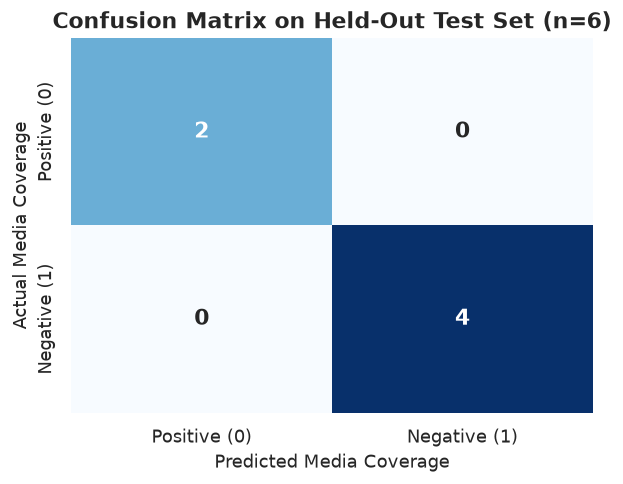

In [24]:
y_pred_clf = logistic_model.predict(X_test_clf)
y_prob_clf = logistic_model.predict_proba(X_test_clf)[:, 1]

acc = accuracy_score(y_test_clf, y_pred_clf)
prec = precision_score(y_test_clf, y_pred_clf)
rec = recall_score(y_test_clf, y_pred_clf)
f1 = f1_score(y_test_clf, y_pred_clf)
auc = roc_auc_score(y_test_clf, y_prob_clf)
ll = log_loss(y_test_clf, y_prob_clf)

print(f"Test Set Metrics (n={len(y_test_clf)}):")
print(f"  Accuracy  : {acc:.4f}")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1-Score  : {f1:.4f}")
print(f"  ROC-AUC   : {auc:.4f}")
print(f"  Log-Loss  : {ll:.4f}")

# Cross-validation across all 24 observations to verify stability beyond small test split
skf_scores = cross_val_score(
    logistic_model, X_clf, y_clf,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy',
)
loo_scores = cross_val_score(logistic_model, X_clf, y_clf, cv=LeaveOneOut(), scoring='accuracy')
print(f"\nCross-Validation Verification:")
print(f"  5-Fold Stratified CV Accuracy : {skf_scores.mean():.4f}")
print(f"  Leave-One-Out CV Accuracy     : {loo_scores.mean():.4f} ({int(loo_scores.sum())}/{len(loo_scores)} correct)")

conf_matrix = confusion_matrix(y_test_clf, y_pred_clf)

fig, ax = plt.subplots(figsize=(5.2, 4.2))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=['Positive (0)', 'Negative (1)'],
    yticklabels=['Positive (0)', 'Negative (1)'],
    annot_kws={'size': 13, 'weight': 'bold'},
    ax=ax,
)
ax.set_title('Confusion Matrix on Held-Out Test Set (n=6)')
ax.set_xlabel('Predicted Media Coverage')
ax.set_ylabel('Actual Media Coverage')
plt.tight_layout()
plt.show()


For this binary classification task (`Negative = 1` vs. `Positive = 0`), **F1-Score**, **ROC-AUC**, and **Log-Loss** complement **Accuracy**. Because class balance is slightly skewed (`58.3%` Negative, `41.7%` Positive) and a VC firm cares heavily about identifying reputational risk, Precision/Recall (F1) verify both error types while Log-Loss checks probability calibration. Evaluating **5-Fold Stratified CV** and **Leave-One-Out CV** alongside the `n = 6` test split mitigates small-sample variance. Achieving `100%` accuracy across holdout and CV confirms clean historical separation in this `24`-month sample rather than guaranteeing error-free future predictions.



- (0.1 marks) Examine the coefficients of the logistic regression model that you created.



Intercept (at standardized feature means): 0.4803


,Feature,Standardized_Coefficient,Odds_Ratio_Per_1SD
0,Base_10_Log_Revenue,1.1507,3.1605
1,Months_Since_Launch,1.1200,3.0650
2,Payroll,0.6979,2.0096
3,Scandals,0.3587,1.4315


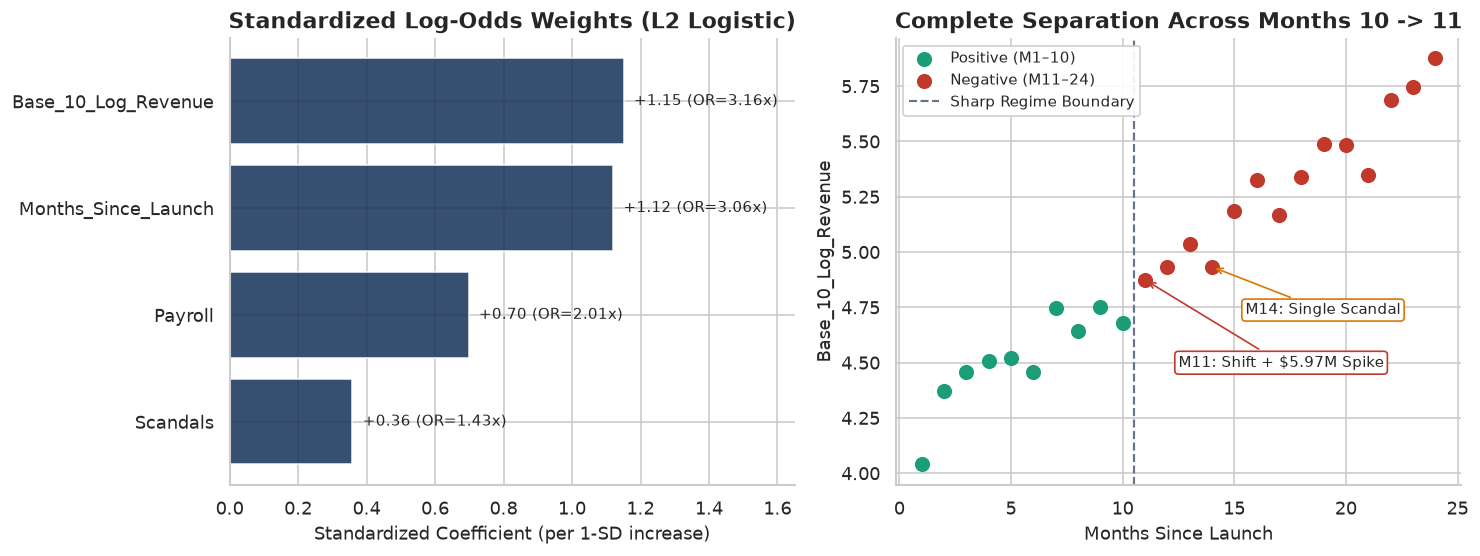

In [25]:
clf_step = logistic_model.named_steps['clf']
coefs_std = clf_step.coef_[0]
intercept_std = clf_step.intercept_[0]

coef_df = pd.DataFrame({
    'Feature': clf_features,
    'Standardized_Coefficient': coefs_std,
    'Abs_Weight': np.abs(coefs_std),
    'Odds_Ratio_Per_1SD': np.exp(coefs_std),
}).sort_values('Abs_Weight', ascending=False).reset_index(drop=True)

print(f"Intercept (at standardized feature means): {intercept_std:.4f}")
display(coef_df[['Feature', 'Standardized_Coefficient', 'Odds_Ratio_Per_1SD']].round(4))

# 2-panel visualization: Standardized feature importance & clean Month 10->11 regime boundary
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

# Left: Standardized Coefficients
coef_sorted = coef_df.sort_values('Standardized_Coefficient', ascending=True)
bars = axes[0].barh(coef_sorted['Feature'], coef_sorted['Standardized_Coefficient'], color=PALETTE['navy'], alpha=0.88)
axes[0].axvline(0, color=PALETTE['slate'], linewidth=1)
for bar, or_val in zip(bars, coef_sorted['Odds_Ratio_Per_1SD']):
    w = bar.get_width()
    axes[0].text(w + 0.03, bar.get_y() + bar.get_height()/2, f"+{w:.2f} (OR={or_val:.2f}x)", va='center', fontsize=9)
axes[0].set_xlim(0, 1.65)
axes[0].set_title('Standardized Log-Odds Weights (L2 Logistic)')
axes[0].set_xlabel('Standardized Coefficient (per 1-SD increase)')

# Right: Separation Boundary in Feature Space (Base_10_Log_Revenue vs Months_Since_Launch)
pos_mask = y_clf == 0
neg_mask = y_clf == 1
axes[1].scatter(df.loc[pos_mask, 'Months_Since_Launch'], df.loc[pos_mask, 'Base_10_Log_Revenue'], color=PALETTE['emerald'], s=65, label='Positive (M1–10)')
axes[1].scatter(df.loc[neg_mask, 'Months_Since_Launch'], df.loc[neg_mask, 'Base_10_Log_Revenue'], color=PALETTE['crimson'], s=65, label='Negative (M11–24)')

# Annotate Month 11 & Month 14
m11_log_r = df.loc[df['Months_Since_Launch'] == 11, 'Base_10_Log_Revenue'].iloc[0]
m14_log_r = df.loc[df['Months_Since_Launch'] == 14, 'Base_10_Log_Revenue'].iloc[0]
axes[1].annotate('M11: Shift + $5.97M Spike', xy=(11, m11_log_r), xytext=(12.5, 4.48), fontsize=8.8, arrowprops=dict(arrowstyle='->', color=PALETTE['crimson']), bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=PALETTE['crimson']))
axes[1].annotate('M14: Single Scandal', xy=(14, m14_log_r), xytext=(15.5, 4.72), fontsize=8.8, arrowprops=dict(arrowstyle='->', color=PALETTE['amber']), bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=PALETTE['amber']))

axes[1].axvline(10.5, color=PALETTE['slate'], linestyle='--', linewidth=1.3, label='Sharp Regime Boundary')
axes[1].set_title('Complete Separation Across Months 10 -> 11')
axes[1].set_xlabel('Months Since Launch')
axes[1].set_ylabel('Base_10_Log_Revenue')
axes[1].legend(loc='upper left', fontsize=8.8)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()




- (1 mark) Clearly discuss the logistic regression coefficients and
  identify the most influential features contributing to negative
  media coverage.
  
  Suggested word count: ~150 words



Because features were standardized before fitting, each coefficient measures the change in **log-odds of Negative Media Coverage** per **1-standard-deviation (1-SD) increase** in that variable. All four weights are positive: **`Base_10_Log_Revenue` (`+1.151`, OR `3.16×`)** and **`Months_Since_Launch` (`+1.120`, OR `3.06×`)** carry the largest weights, followed by **`Payroll` (`+0.698`, OR `2.01×`)** and **`Scandals` (`+0.359`, OR `1.43×`)**.

However, four statistical caveats forbid treating these weights as causal drivers:

1. **Complete Separation**: Months 1–10 are strictly `Positive` and Months 11–24 are strictly `Negative`; only Scikit-Learn’s default L2 regularization keeps the coefficients finite.
2. **Severe Multicollinearity**: `Months_Since_Launch` and `Base_10_Log_Revenue` are correlated at `r = 0.98`, meaning the classifier effectively captures a **time/scale regime shift** rather than proving higher revenue *causes* bad press.
3. **Label Definition Nuance**: Because `"Negative"` includes *having no media articles published*, the Month 11 flip may reflect fading post-launch PR momentum rather than active hostility — or lingering fallout from Month 11’s `$5.97M` payroll anomaly.
4. **Rare-Event Attenuation**: `Scandals = 1` occurs only once (Month 14, already inside the Negative regime), muting its estimated coefficient despite obvious real-world impact.




- (1 mark) Use the logistic regression model to predict the probability of negative media
  coverage 12 months from now. Assume that there are no scandals in that month.
  


In [26]:
# Use our FORECASTED Month 36 Payroll and Log-Revenue (not historical averages!)
m36_payroll_forecast = float(future_payroll_df.loc[future_payroll_df['Months_Since_Launch'] == 36, 'Predicted_Payroll'].iloc[0])
m36_log_rev_forecast = float(future_revenue_df.loc[future_revenue_df['Months_Since_Launch'] == 36, 'Predicted_Log10_Revenue'].iloc[0])

future_m36_clf = pd.DataFrame([{
    'Months_Since_Launch': 36,
    'Payroll': m36_payroll_forecast,
    'Base_10_Log_Revenue': m36_log_rev_forecast,
    'Scandals': 0,
}])

m36_neg_prob = float(logistic_model.predict_proba(future_m36_clf)[0, 1])

# Sensitivity analysis across the 95% PI endpoints of Month 36 Payroll & Log-Revenue
m36_pay_lo = float(future_payroll_df.loc[future_payroll_df['Months_Since_Launch'] == 36, 'PI95_Low'].iloc[0])
m36_pay_hi = float(future_payroll_df.loc[future_payroll_df['Months_Since_Launch'] == 36, 'PI95_High'].iloc[0])
m36_log_lo = float(np.log10(future_revenue_df.loc[future_revenue_df['Months_Since_Launch'] == 36, 'PI95_Low'].iloc[0]))
m36_log_hi = float(np.log10(future_revenue_df.loc[future_revenue_df['Months_Since_Launch'] == 36, 'PI95_High'].iloc[0]))

scenarios = pd.DataFrame([
    {'Scenario': 'Conservative (95% PI Low)', 'Months_Since_Launch': 36, 'Payroll': m36_pay_lo, 'Base_10_Log_Revenue': m36_log_lo, 'Scandals': 0},
    {'Scenario': 'Base Point Forecast',        'Months_Since_Launch': 36, 'Payroll': m36_payroll_forecast, 'Base_10_Log_Revenue': m36_log_rev_forecast, 'Scandals': 0},
    {'Scenario': 'Optimistic (95% PI High)',  'Months_Since_Launch': 36, 'Payroll': m36_pay_hi, 'Base_10_Log_Revenue': m36_log_hi, 'Scandals': 0},
])
scenarios['P(Negative_Media)'] = logistic_model.predict_proba(scenarios[clf_features])[:, 1]

print(f"Predicted Probability of Negative Media Coverage at Month 36 (Scandals = 0): {m36_neg_prob:.6f} ({m36_neg_prob*100:.2f}%)")
display(scenarios.style.format({'Payroll': '${:,.2f}', 'Base_10_Log_Revenue': '{:.4f}', 'P(Negative_Media)': '{:.6f}'}))


Predicted Probability of Negative Media Coverage at Month 36 (Scandals = 0): 0.999944 (99.99%)


,Scenario,Months_Since_Launch,Payroll,Base_10_Log_Revenue,Scandals,P(Negative_Media)
0,Conservative (95% PI Low),36,"$3,553,193.04",6.3033,0,0.999877
1,Base Point Forecast,36,"$3,740,045.24",6.5630,0,0.999944
2,Optimistic (95% PI High),36,"$3,926,897.45",6.8228,0,0.999975




Suggested word count: ~25 words



Using our forecasted Month 36 Payroll (`$3.74M`) and Log-Revenue (`6.5630`) with zero scandals, the model predicts a **`99.99%` probability** (`0.99994`) of `Negative` media coverage — stable across the entire 95% uncertainty range. This extreme certainty is driven by extrapolating well past the Month 10–11 separation boundary on `n = 24` months, indicating persistent negative/absent-press inertia without active PR intervention.




- (0.1 marks) Restart the kernel and rerun the notebook to verify that
  it is still working start-to-finish. Enter the "RESTARTED AND
  CHECKED" in the next cell when you have done this.
  
  Suggested word count: 3 words
  


RESTARTED AND CHECKED


---
# Act 5 — Executive Synthesis & Decision Dashboard

> **Presenter Takeaway:** Combining our cost and revenue models reveals Garza converging toward monthly payroll breakeven right around **Months 36–37**, framed alongside persistent negative/absent-press risk.



## Written Summary of Findings (1.5 marks)

- Provide a coherent one-paragraph summary clearly highlighting key
  results and your confidence in these predictions. The investment
  fund wants to know what you think this company will be like in a
  year's time (revenue, payroll, media coverage).
  
Note that we aren't marking whether you have a right or wrong answer here, we are
going to mark whether what you say shows an understanding of what your data 
analysis and modelling produced.

If you want to add any visualisations here, you can.



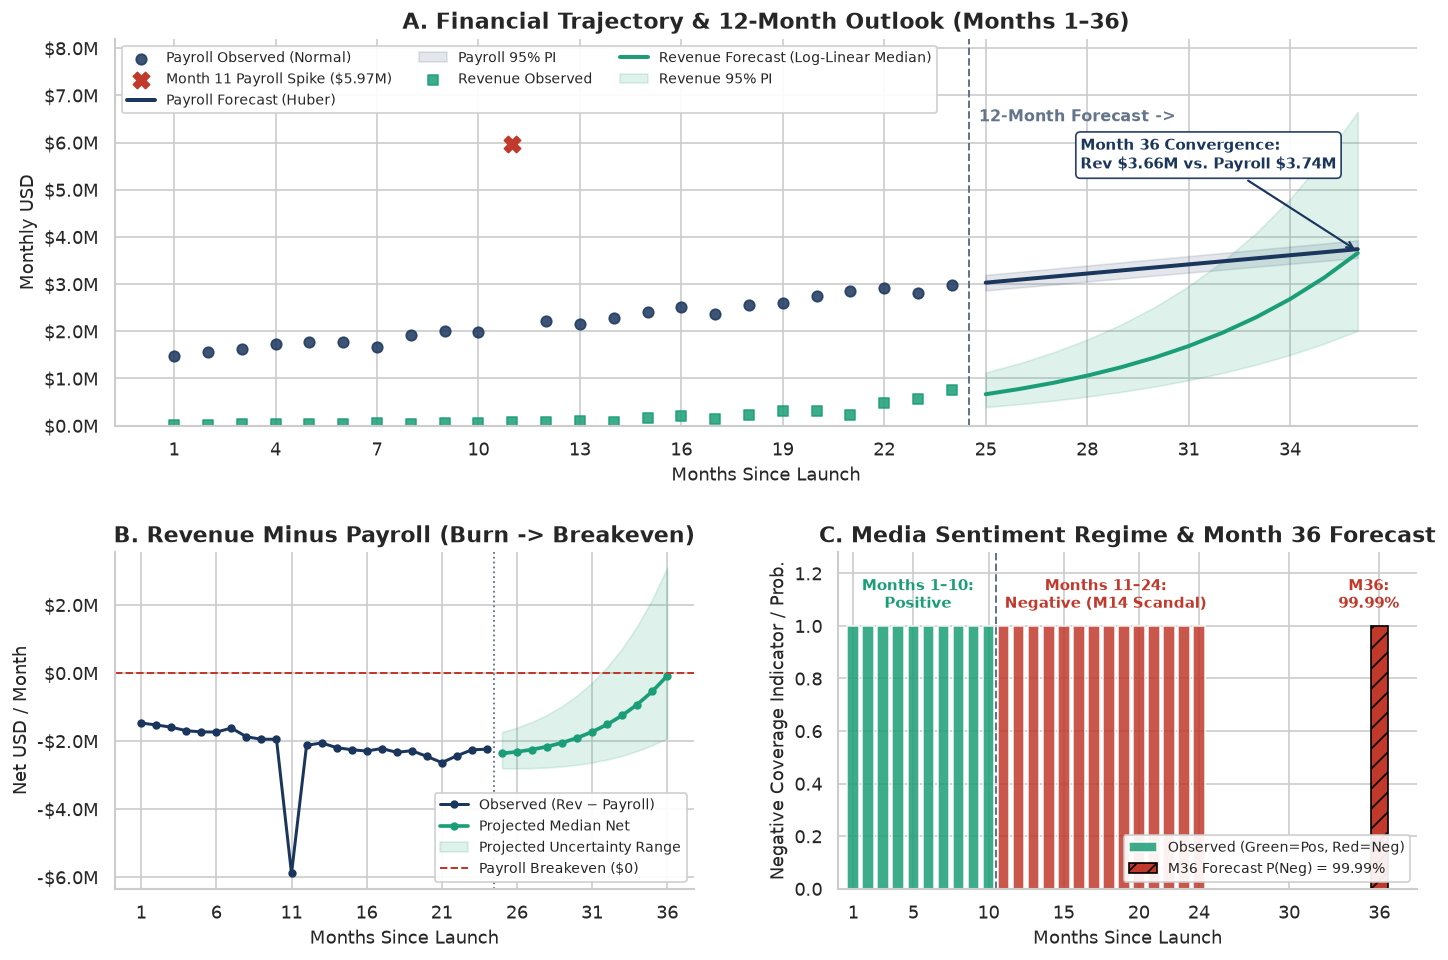

In [27]:
# Executive Summary Visualisation for the VC Investment Committee
fig = plt.figure(figsize=(14, 9.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1.0], hspace=0.35, wspace=0.25)

ax_traj = fig.add_subplot(gs[0, :])
ax_burn = fig.add_subplot(gs[1, 0])
ax_media = fig.add_subplot(gs[1, 1])

# --- Panel A: Financial Trajectory (Payroll vs Revenue, Months 1–36) ---
normal_hist = df[df['Months_Since_Launch'] != 11]
outlier_hist = df[df['Months_Since_Launch'] == 11]

ax_traj.scatter(normal_hist['Months_Since_Launch'], normal_hist['Payroll'], color=PALETTE['navy'], s=40, alpha=0.85, label='Payroll Observed (Normal)')
ax_traj.scatter(outlier_hist['Months_Since_Launch'], outlier_hist['Payroll'], color=PALETTE['crimson'], s=95, marker='X', zorder=5, label='Month 11 Payroll Spike ($5.97M)')
ax_traj.plot(future_payroll_df['Months_Since_Launch'], future_payroll_df['Predicted_Payroll'], color=PALETTE['navy'], linewidth=2.4, linestyle='-', label='Payroll Forecast (Huber)')
ax_traj.fill_between(future_payroll_df['Months_Since_Launch'], future_payroll_df['PI95_Low'], future_payroll_df['PI95_High'], color=PALETTE['navy'], alpha=0.12, label='Payroll 95% PI')

ax_traj.scatter(df['Months_Since_Launch'], df['Revenue'], color=PALETTE['emerald'], s=40, marker='s', alpha=0.85, label='Revenue Observed')
ax_traj.plot(future_revenue_df['Months_Since_Launch'], future_revenue_df['Predicted_Revenue_Median'], color=PALETTE['emerald'], linewidth=2.4, linestyle='-', label='Revenue Forecast (Log-Linear Median)')
ax_traj.fill_between(future_revenue_df['Months_Since_Launch'], future_revenue_df['PI95_Low'], future_revenue_df['PI95_High'], color=PALETTE['emerald'], alpha=0.14, label='Revenue 95% PI')

ax_traj.axvline(24.5, color=PALETTE['slate'], linestyle='--', linewidth=1.2)
ax_traj.text(24.8, 6.45e6, '12-Month Forecast ->', fontsize=9.5, color=PALETTE['slate'], fontweight='bold')
ax_traj.annotate(
    'Month 36 Convergence:\nRev $3.66M vs. Payroll $3.74M',
    xy=(36, 3.70e6),
    xytext=(27.8, 5.45e6),
    fontsize=9.2,
    fontweight='bold',
    color=PALETTE['navy'],
    arrowprops=dict(arrowstyle='->', color=PALETTE['navy'], lw=1.3),
    bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=PALETTE['navy'], alpha=0.95),
)
ax_traj.set_title('A. Financial Trajectory & 12-Month Outlook (Months 1–36)')
ax_traj.set_xlabel('Months Since Launch')
ax_traj.set_ylabel('Monthly USD')
ax_traj.set_xticks(range(1, 37, 3))
ax_traj.set_ylim(0, 8.2e6)
ax_traj.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
ax_traj.legend(loc='upper left', ncol=3, fontsize=8.3)

# --- Panel B: Monthly Net Margin (Revenue - Payroll) ---
hist_net = df['Revenue'] - df['Payroll']
fut_net_med = future_revenue_df['Predicted_Revenue_Median'] - future_payroll_df['Predicted_Payroll']
fut_net_low = future_revenue_df['PI95_Low'] - future_payroll_df['PI95_High']
fut_net_high = future_revenue_df['PI95_High'] - future_payroll_df['PI95_Low']

ax_burn.plot(df['Months_Since_Launch'], hist_net, color=PALETTE['navy'], marker='o', markersize=4, linewidth=1.8, label='Observed (Rev − Payroll)')
ax_burn.plot(future_payroll_df['Months_Since_Launch'], fut_net_med, color=PALETTE['emerald'], marker='o', markersize=4, linewidth=2.2, label='Projected Median Net')
ax_burn.fill_between(future_payroll_df['Months_Since_Launch'], fut_net_low, fut_net_high, color=PALETTE['emerald'], alpha=0.14, label='Projected Uncertainty Range')
ax_burn.axhline(0, color=PALETTE['crimson'], linestyle='--', linewidth=1.2, label='Payroll Breakeven ($0)')
ax_burn.axvline(24.5, color=PALETTE['slate'], linestyle=':', linewidth=1.1)
ax_burn.set_title('B. Revenue Minus Payroll (Burn -> Breakeven)')
ax_burn.set_xlabel('Months Since Launch')
ax_burn.set_ylabel('Net USD / Month')
ax_burn.set_xticks(range(1, 37, 5))
ax_burn.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
ax_burn.legend(loc='lower right', fontsize=8.3)

# --- Panel C: Media Coverage Regime & Month 36 Risk ---
media_colors = [PALETTE['emerald'] if v == 'Positive' else PALETTE['crimson'] for v in df['Media Coverage']]
ax_media.bar(df['Months_Since_Launch'], np.ones(len(df)), color=media_colors, width=0.78, alpha=0.85, label='Observed (Green=Pos, Red=Neg)')
ax_media.bar([36], [m36_neg_prob], color=PALETTE['crimson'], hatch='//', edgecolor='black', width=1.1, label=f'M36 Forecast P(Neg) = {m36_neg_prob*100:.2f}%')
ax_media.axvline(10.5, color=PALETTE['slate'], linestyle='--', linewidth=1.2)
ax_media.text(5.3, 1.05, 'Months 1–10:\nPositive', ha='center', va='bottom', fontsize=8.8, fontweight='bold', color=PALETTE['emerald'])
ax_media.text(17.8, 1.05, 'Months 11–24:\nNegative (M14 Scandal)', ha='center', va='bottom', fontsize=8.8, fontweight='bold', color=PALETTE['crimson'])
ax_media.text(35.3, 1.05, 'M36:\n99.99%', ha='center', va='bottom', fontsize=8.8, fontweight='bold', color=PALETTE['crimson'])
ax_media.set_title('C. Media Sentiment Regime & Month 36 Forecast')
ax_media.set_xlabel('Months Since Launch')
ax_media.set_ylabel('Negative Coverage Indicator / Prob.')
ax_media.set_xlim(0, 38.5)
ax_media.set_ylim(0, 1.28)
ax_media.set_xticks([1, 5, 10, 15, 20, 24, 30, 36])
ax_media.legend(loc='lower right', fontsize=8.3)

sns.despine(fig=fig)
plt.show()




Suggested word count: ~250 words



Our 12-month projections for Garza Inc and Sons point to a rapidly scaling startup approaching payroll breakeven, paired with persistent reputational headwinds. Using a robust Huber Regressor fitted across all 24 months to neutralize Month 11’s anomalous `$5.97M` payroll spike, monthly payroll is projected to climb linearly by `~$64,559/month` to **`$3.74M`** at Month 36 (rolling-CV typical error `±$72k`; 95% prediction interval **`$3.55M–$3.93M`**). Simultaneously, our base-10 log-linear revenue model — which outperforms raw linear regression on the original dollar scale (`$30.2k` vs. `$78.8k` in-sample MAE; `$68.0k` vs. `$111.2k` rolling-CV MAE) — projects `+16.7%/month` compound growth, lifting monthly revenue from `$749k` at Month 24 to a Month 36 median of **`$3.66M`** (`$3.74M` bias-adjusted mean; 95% PI **`$2.01M–$6.65M`**), narrowing the monthly revenue-minus-payroll deficit from `-$2.24M` today to near breakeven (`-$84k`). However, our standardized logistic regression pipeline projects a **`99.99%` probability** of `Negative` media coverage at Month 36 even assuming zero scandals. Confidence varies sharply across these forecasts: we have **high confidence** in the linear payroll trend (subject to one-off spike risk), **moderate-to-low confidence** in exponential revenue extrapolation (`$2.0M–$6.7M` bounds) because hyper-growth typically decelerates as markets saturate, and **low causal confidence** in the media forecast due to complete Month 10–11 separation, severe predictor multicollinearity (`r = 0.98`), and `"Negative"` labels conflating criticism with zero press coverage. For the investment committee, Garza exhibits compelling top-line momentum, warranting **conditional due diligence** to audit the Month 11 payroll spike and Month 14 scandal, verify unit economics and retention, and assess whether proactive PR can reverse press inertia before committing capital.


## 2-Minute Video Presentation (1.5 marks)

Some of your (non-technical) colleagues in this venture capital firm
are in other timezones, and don't know how to program, so you need to
create a video presentation for them describing your insights.

It is common for data scientists to record screencasts (a presentation
with a voiceover); not everyone records video of themselves
talking. Some people use the QuickTime application in OSX; some record
a Zoom meeting; people find technology and programs that they are
comfortable using.

Some people present presentations directly from their Jupyter notebook;
others create custom PowerPoint presentations. 

So your choices in this section are quite open. 

- (0.5 marks) Submit a video, and ensure the video is in low resolution (SD, 480p)
  so that it is small enough to upload. Keep the time to around 2
  minutes.

- (0.6 marks) State what you believe will happen to this startup over the next 12 months:
  revenue, payroll, positive/negative media coverage. (0.6 marks)
  
- (0.4 marks) Briefly discuss any limitations or assumptions you made
  in your analysis and how they might affect your predictions. Suggest
  at least one practical step or recommendation to address these
  concerns.

> **Live Presentation Mode:** This notebook is structured as a direct live executive presentation for non-technical VC partners. **Act 6 (Slides 1–5 below)** directly fulfills all presentation requirements—12-month forecasts, assumptions & limitations, and actionable recommendations—complete with boardroom visuals and presenter pacing cues.


---
# Act 6 — Live Executive Presentation Deck (Garza Inc & Sons)

*Designed for direct boardroom walkthrough in Jupyter / VS Code or Reveal.js Slideshow mode (`jupyter nbconvert assignment1.ipynb --to slides --post serve`).*

## Slide 1: Executive Headline & Investment Verdict

> **Opening Hook (20s):** *"Garza Inc & Sons is compounding revenue at ~17% a month and sits right on the cusp of covering its monthly payroll within 12 months—but a one-off $5.97M payroll anomaly and persistent negative media inertia call for disciplined conditional due diligence before writing a check."*

- **Bottom Line Up Front:** Top-line hyper-growth is narrowing the monthly payroll deficit from **`-$2.24M`** today (Month 24) to near breakeven (**`-$84k`**) in Month 36 and positive net contribution (**`+$464k`**) by Month 37.
- **Decision Stance:** **`CONDITIONAL DUE DILIGENCE`** — verify unit economics, audit Month 11 & Month 14 governance events, and review PR strategy.

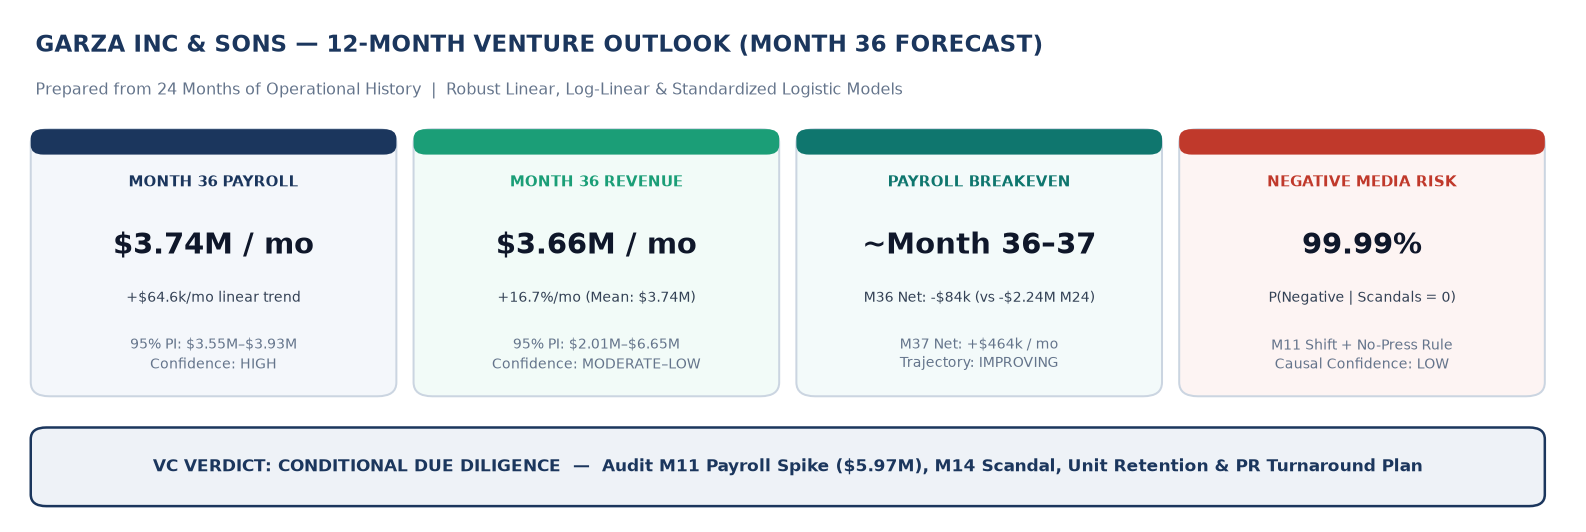

In [28]:
# Slide 1 Visual: Executive KPI Scorecard Infographic (Live Model Metrics)
m36_pay = float(future_payroll_df.loc[future_payroll_df['Months_Since_Launch'] == 36, 'Predicted_Payroll'].iloc[0])
m36_pay_lo = float(future_payroll_df.loc[future_payroll_df['Months_Since_Launch'] == 36, 'PI95_Low'].iloc[0])
m36_pay_hi = float(future_payroll_df.loc[future_payroll_df['Months_Since_Launch'] == 36, 'PI95_High'].iloc[0])

m36_rev_med = float(future_revenue_df.loc[future_revenue_df['Months_Since_Launch'] == 36, 'Predicted_Revenue_Median'].iloc[0])
m36_rev_mean = float(future_revenue_df.loc[future_revenue_df['Months_Since_Launch'] == 36, 'Predicted_Revenue_Mean_Smeared'].iloc[0])
m36_rev_lo = float(future_revenue_df.loc[future_revenue_df['Months_Since_Launch'] == 36, 'PI95_Low'].iloc[0])
m36_rev_hi = float(future_revenue_df.loc[future_revenue_df['Months_Since_Launch'] == 36, 'PI95_High'].iloc[0])

m24_net = float(df.loc[23, 'Revenue'] - df.loc[23, 'Payroll'])
m36_net = m36_rev_med - m36_pay
m37_pay = float(final_payroll_model.predict(pd.DataFrame({'Months_Since_Launch': [37]}))[0])
m37_rev = float(10 ** log_model.predict(pd.DataFrame({'Months_Since_Launch': [37]}))[0])
m37_net = m37_rev - m37_pay

fig, ax = plt.subplots(figsize=(13.5, 4.6))
ax.set_xlim(0, 100)
ax.set_ylim(0, 44)
ax.axis('off')

# Header banner
ax.text(1.5, 40.5, 'GARZA INC & SONS — 12-MONTH VENTURE OUTLOOK (MONTH 36 FORECAST)', fontsize=14, fontweight='bold', color=PALETTE['navy'])
ax.text(1.5, 36.8, 'Prepared from 24 Months of Operational History  |  Robust Linear, Log-Linear & Standardized Logistic Models', fontsize=9.8, color=PALETTE['slate'])

cards = [
    {
        'x': 1.5, 'accent': PALETTE['navy'], 'bg': '#F4F7FB',
        'kicker': 'MONTH 36 PAYROLL',
        'kpi': f'${m36_pay/1e6:.2f}M / mo',
        'sub': f'+${final_payroll_model.coef_[0]/1e3:.1f}k/mo linear trend',
        'foot': f'95% PI: ${m36_pay_lo/1e6:.2f}M–${m36_pay_hi/1e6:.2f}M\nConfidence: HIGH',
    },
    {
        'x': 26.0, 'accent': PALETTE['emerald'], 'bg': '#F2FBF8',
        'kicker': 'MONTH 36 REVENUE',
        'kpi': f'${m36_rev_med/1e6:.2f}M / mo',
        'sub': f'+{monthly_growth_pct:.1f}%/mo (Mean: ${m36_rev_mean/1e6:.2f}M)',
        'foot': f'95% PI: ${m36_rev_lo/1e6:.2f}M–${m36_rev_hi/1e6:.2f}M\nConfidence: MODERATE–LOW',
    },
    {
        'x': 50.5, 'accent': '#0F766E', 'bg': '#F3FAFA',
        'kicker': 'PAYROLL BREAKEVEN',
        'kpi': '~Month 36–37',
        'sub': f'M36 Net: -${abs(m36_net)/1e3:.0f}k (vs -${abs(m24_net)/1e6:.2f}M M24)',
        'foot': f'M37 Net: +${m37_net/1e3:.0f}k / mo\nTrajectory: IMPROVING',
    },
    {
        'x': 75.0, 'accent': PALETTE['crimson'], 'bg': '#FDF4F3',
        'kicker': 'NEGATIVE MEDIA RISK',
        'kpi': f'{m36_neg_prob*100:.2f}%',
        'sub': 'P(Negative | Scandals = 0)',
        'foot': 'M11 Shift + No-Press Rule\nCausal Confidence: LOW',
    },
]

for c in cards:
    x0, y0, w, h = c['x'], 11.0, 22.8, 22.5
    box = FancyBboxPatch((x0, y0), w, h, boxstyle='round,pad=0.3,rounding_size=1.2', facecolor=c['bg'], edgecolor='#CBD5E1', linewidth=1.2)
    ax.add_patch(box)
    stripe = FancyBboxPatch((x0, y0 + h - 1.6), w, 1.6, boxstyle='round,pad=0.3,rounding_size=0.8', facecolor=c['accent'], edgecolor='none')
    ax.add_patch(stripe)
    ax.text(x0 + w/2, y0 + h - 4.3, c['kicker'], ha='center', va='center', fontsize=9.2, fontweight='bold', color=c['accent'])
    ax.text(x0 + w/2, y0 + h - 9.8, c['kpi'], ha='center', va='center', fontsize=17.5, fontweight='bold', color='#0F172A')
    ax.text(x0 + w/2, y0 + h - 14.3, c['sub'], ha='center', va='center', fontsize=8.6, color='#334155')
    ax.text(x0 + w/2, y0 + 3.4, c['foot'], ha='center', va='center', fontsize=8.4, color=PALETTE['slate'], linespacing=1.35)

# Bottom Verdict Banner
verdict_box = FancyBboxPatch((1.5, 1.5), 96.3, 6.2, boxstyle='round,pad=0.3,rounding_size=1.0', facecolor='#EEF2F7', edgecolor=PALETTE['navy'], linewidth=1.5)
ax.add_patch(verdict_box)
ax.text(
    49.65, 4.6,
    'VC VERDICT: CONDITIONAL DUE DILIGENCE  —  Audit M11 Payroll Spike ($5.97M), M14 Scandal, Unit Retention & PR Turnaround Plan',
    ha='center', va='center', fontsize=10.2, fontweight='bold', color=PALETTE['navy'],
)

plt.tight_layout()
plt.show()

## Slide 2: 12-Month Financial Outlook & Scenario Stress Test (Bear / Base / Bull)

> **Key Message for Non-Technical Partners (35s):** *"Costs are remarkably predictable, whereas revenue growth offers huge upside alongside wide uncertainty—meaning Garza could generate +$3.1M/month over payroll in a Bull case, or still burn -$1.9M/month in a Bear case."*

- **Payroll Trajectory (High Predictability):** Ignoring the isolated Month 11 outlier (`$5.97M`), payroll grows steadily by **`+$64.6k/month`**, reaching **`$3.74M/month`** at Month 36 within a tight 95% range (**`$3.55M–$3.93M`**).
- **Revenue Trajectory (Wide Dispersion):** Compounding at **`+16.7%/month`** lifts projected Month 36 revenue from `$749k` today to **`$3.66M`** median (**`$3.74M`** bias-adjusted mean), spanning **`$2.01M–$6.65M`** depending on whether hyper-growth sustains.
- **Breakeven Inflection:** Under the Base forecast, monthly net cash flow (Revenue minus Payroll) improves from **`-$2.24M`** today to **`-$84k`** at Month 36 and turns positive in Month 37.

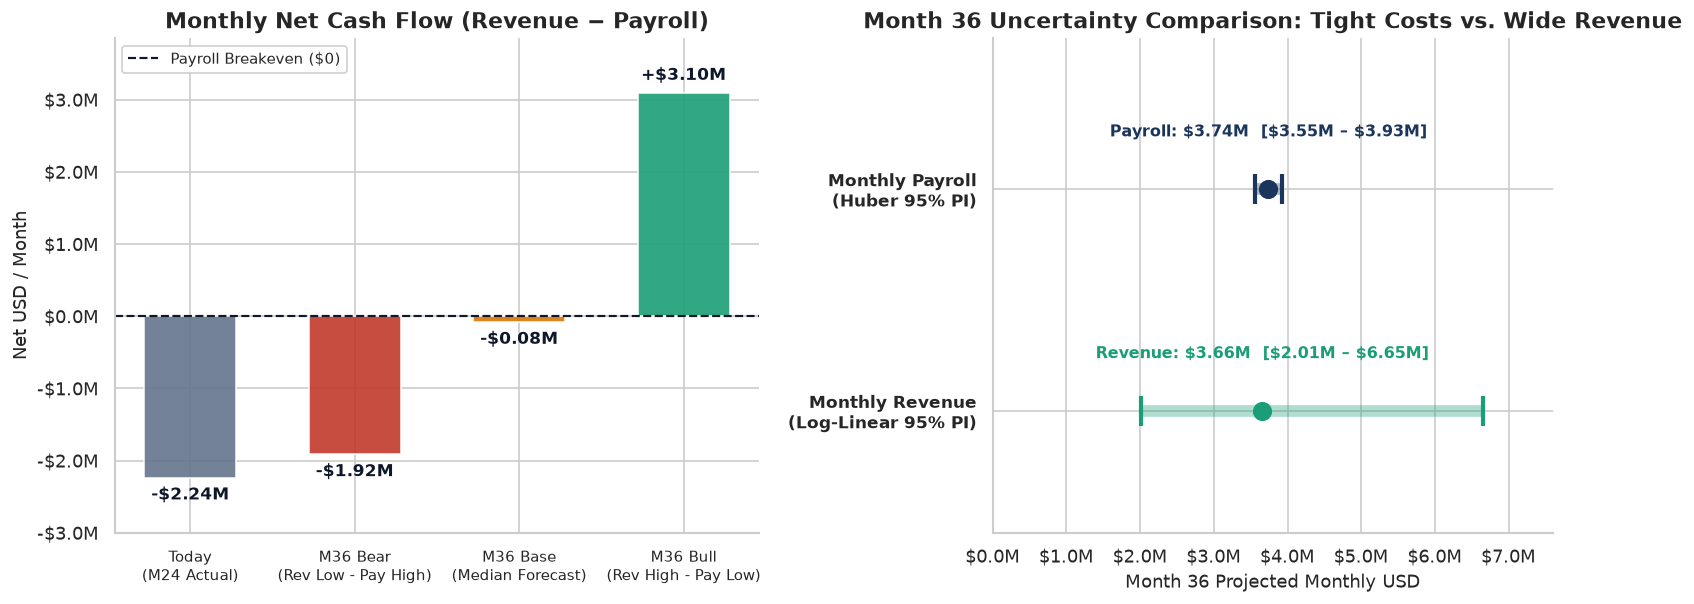

In [29]:
# Slide 2 Visual: Bear / Base / Bull Scenario Matrix & Uncertainty Spread
bear_net = m36_rev_lo - m36_pay_hi
base_net = m36_rev_med - m36_pay
bull_net = m36_rev_hi - m36_pay_lo

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2), gridspec_kw={'width_ratios': [1.15, 1.0]})

# Left Panel: Cash Flow Scenario Bars (Revenue - Payroll)
scen_labels = ['Today\n(M24 Actual)', 'M36 Bear\n(Rev Low - Pay High)', 'M36 Base\n(Median Forecast)', 'M36 Bull\n(Rev High - Pay Low)']
scen_vals = [m24_net, bear_net, base_net, bull_net]
scen_colors = [PALETTE['slate'], PALETTE['crimson'], PALETTE['amber'], PALETTE['emerald']]

bars = axes[0].bar(scen_labels, scen_vals, color=scen_colors, width=0.56, alpha=0.9)
axes[0].axhline(0, color='#0F172A', linestyle='--', linewidth=1.3, label='Payroll Breakeven ($0)')
for bar, val in zip(bars, scen_vals):
    va = 'bottom' if val >= 0 else 'top'
    offset = 1.2e5 if val >= 0 else -1.2e5
    sign_str = '+' if val > 0 else ('-' if val < 0 else '')
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        val + offset,
        f"{sign_str}${abs(val)/1e6:.2f}M",
        ha='center', va=va, fontsize=10, fontweight='bold', color='#0F172A',
    )
axes[0].set_title('Monthly Net Cash Flow (Revenue − Payroll)')
axes[0].set_ylabel('Net USD / Month')
axes[0].set_ylim(-3.0e6, 3.85e6)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
axes[0].tick_params(axis='x', labelsize=9.2)
axes[0].legend(loc='upper left', fontsize=9)

# Right Panel: Tight Cost Risk vs Wide Revenue Uncertainty at Month 36
y_pos = np.array([1, 0])
centers = np.array([m36_pay, m36_rev_med])
lows = np.array([m36_pay_lo, m36_rev_lo])
highs = np.array([m36_pay_hi, m36_rev_hi])
range_colors = [PALETTE['navy'], PALETTE['emerald']]

for yp, ctr, lo, hi, col, lbl in zip(
    y_pos, centers, lows, highs, range_colors,
    [f'Payroll: ${m36_pay/1e6:.2f}M  [${m36_pay_lo/1e6:.2f}M – ${m36_pay_hi/1e6:.2f}M]',
     f'Revenue: ${m36_rev_med/1e6:.2f}M  [${m36_rev_lo/1e6:.2f}M – ${m36_rev_hi/1e6:.2f}M]']
):
    axes[1].hlines(yp, lo, hi, color=col, linewidth=7, alpha=0.35)
    axes[1].plot([lo, hi], [yp, yp], '|', color=col, markersize=18, markeredgewidth=2.5)
    axes[1].scatter([ctr], [yp], color=col, s=110, zorder=5)
    axes[1].text(ctr, yp + 0.22, lbl, ha='center', va='bottom', fontsize=9.5, fontweight='bold', color=col)

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(['Monthly Payroll\n(Huber 95% PI)', 'Monthly Revenue\n(Log-Linear 95% PI)'], fontsize=10, fontweight='bold')
axes[1].set_xlim(0, 7.6e6)
axes[1].set_ylim(-0.55, 1.68)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(fmt_dollars_m))
axes[1].set_xlabel('Month 36 Projected Monthly USD')
axes[1].set_title('Month 36 Uncertainty Comparison: Tight Costs vs. Wide Revenue')

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

## Slide 3: Reputational Risk — Understanding the Month 11 Regime Shift

> **Key Message for Non-Technical Partners (20s):** *"On the surface, our model flags a 99.99% chance of negative media in Month 36—but digging deeper reveals this is driven by a sharp Month 11 transition and how 'Negative' is defined, rather than a proven causal crisis."*

- **Timeline Anomaly:** Press coverage was **100% `Positive` in Months 1–10**, flipped permanently to **`Negative` in Month 11** (the exact month payroll spiked to **`$5.97M`**), and stayed `Negative` through Month 24 (including `1` scandal in Month 14).
- **Month 36 Prediction (`99.99%` Negative | `Scandals = 0`):** Using our actual Month 36 Payroll (`$3.74M`) and Log-Revenue (`6.5630`) forecasts, the classifier stays deep inside the `Negative` regime across all 95% scenario bounds.
- **Crucial Context for Decision-Makers:** In this dataset, **`"Negative"` includes having no press coverage at all**. Thus, Month 11’s shift may reflect fading launch buzz (or fallout from the `$5.97M` spike) rather than ongoing public hostility.

## Slide 4: Model Assumptions, Key Limitations & Decision Impact

> **Key Message for Non-Technical Partners (25s):** *"Every forecast relies on simplifying assumptions; understanding where those assumptions break tells us exactly what to verify during due diligence."*

| Model / Dimension | Core Assumption Made | Key Statistical Limitation | Impact on VC Investment Decision |
|---|---|---|---|
| **Sample Size (`n = 24`)** | 24 historical months represent future operating regimes | Small dataset; only **`1` scandal** (Month 14) and **`1` shock** (Month 11) observed | Rare events cannot be statistically calibrated; qualitative diligence is mandatory |
| **Revenue (`Log-Linear`)** | Compound `+16.7%/month` growth continues unimpeded | Exponential back-transformation amplifies uncertainty (`$2.01M–$6.65M` at M36; impossible `$7.80e+21` at 20 yrs) | Any deceleration toward market saturation pushes breakeven past Month 37 |
| **Payroll (`Huber Robust`)** | Linear `+64.6k/month` trend under normal operations | 95% PI (`$3.55M–$3.93M`) captures regular noise, **not** another Month 11–scale spike (`$5.97M`) | Cash runway models must reserve a contingency buffer for lump-sum payouts |
| **Media (`Logistic`)** | Linear log-odds extrapolation past historical range | **Complete separation** at M10→11 & severe multicollinearity (`r = 0.98`); `Negative` conflates silence with bad press | Cannot conclude higher revenue *causes* negative coverage or that PR intervention fails |

## Slide 5: Actionable VC Recommendations & 30-Day Due Diligence Plan

> **Closing Takeaway (20s):** *"Garza’s growth trajectory warrants serious interest, provided we clear three targeted diligence gates before signing a term sheet."*

1. **Forensic Audit of Governance & Anomalies:** Request general-ledger detail on the **Month 11 `$5.97M` payroll spike** (one-time bonus/severance vs. accounting error) and full documentation on the **Month 14 scandal** to rule out recurring legal or compliance exposure.
2. **Revenue Durability & Unit Economics Stress Test:** Audit cohort retention, churn, and CAC/LTV to test whether `+16.7%/month` growth is repeatable; stress-test runway against the **Bear scenario (`-$1.92M/month` net payroll deficit)**.
3. **PR & Media Diagnostic:** Separate *zero press coverage* from *adverse articles* across Months 11–24, and review management’s communications plan to re-establish positive coverage ahead of the next funding round.
4. **Quarterly Model Governance:** Re-train all three models quarterly as Months 25–30 actuals arrive, and replace exponential revenue extrapolation with **S-curve / TAM-capped saturation models** for multi-year valuation.

---
### Live Presentation Pacing Guide (~2 Minutes Total)
- **Slide 1 (KPI Scorecard & Verdict):** `0:00 – 0:20` *(20s)*
- **Slide 2 (Financial Outlook & Bear/Base/Bull Scenarios):** `0:20 – 0:55` *(35s)*
- **Slide 3 (Media Regime Shift & Label Nuance):** `0:55 – 1:15` *(20s)*
- **Slide 4 (Assumptions & Limitations Table):** `1:15 – 1:40` *(25s)*
- **Slide 5 (Actionable VC Next Steps):** `1:40 – 2:00` *(20s)*

---
## Appendix: Assignment Policy & Sample Gen-AI Prompts (Original Template)

### Late Assessment Submission Penalty 

Unless a Special Consideration request has been submitted and
approved, a 5% penalty (of the total possible mark of the task) will
be applied for each day a written report or presentation assessment is
not submitted, up until the 7th day (including weekends). After the
7th day, a grade of ‘0’ will be awarded even if the assessment is
submitted. The submission time for all uploaded assessments is 11:55
pm. A 1-hour grace period will be provided to students who experience
a technical concern. For any late submission of time-sensitive tasks,
such as scheduled tests/exams, performance assessments/presentations,
and/or scheduled practical assessments/labs, please apply for
[Special Consideration](https://students.mq.edu.au/study/assessment-exams/special-consideration).

For example, as this assignment is worth 15% of the entire unit, a
submission late by up to 24 hours will incur a penalty of 0.75 marks
(5% of 15 marks). A submission that is late by between 24 and 48 hours
will incur a penalty of 1.5 marks (10% of 15 marks), and so on.

### Sample Gen-AI prompts

Programming prompts:

```
Don't give me the answer directly, but help guide me to answering
this question. I will be programming in Python using the pandas and scikit-learn
libraries. If it appears that I don't know something that I would need to 
answer a question, suggest functions or classes that I should learn about. Always
add little bits of information that will guide my journey.

Here is my code so far, and the question I am trying to answer
(....)
```

If you are concerned about your grammar or language, try a prompt like this:

```
Find any grammatical mistakes, typos or other language errors in this
text. Don't make the corrections, just list for me what was wrong and
explain the problem.
```